# Setup

In [39]:

import pandas as pd
import seaborn as sns


from scipy.signal import welch
import numpy as np
import os
import matplotlib.pyplot as plt

from matplotlib.colors import Normalize

from pathlib import Path




In [40]:

FIG_WIDTH = 7.5
MY_FONT_SIZE = 9

plt.rcParams.update({
    # --- Fonts ---
    "font.family": "Arial",
    "font.size": MY_FONT_SIZE,

    # --- Legend ---
    "legend.fontsize": MY_FONT_SIZE,
    "legend.frameon": False,

    # --- Titles ---
    "figure.titlesize": MY_FONT_SIZE,
    "axes.titleweight": "normal",
    "axes.titlesize": MY_FONT_SIZE,

    # --- Axes ---
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": True,
    "axes.spines.bottom": True,
    "axes.edgecolor": "black",
    "axes.linewidth": 0.8,
    "axes.unicode_minus": True,
    "axes.labelsize": MY_FONT_SIZE,

    # --- Lines & markers ---
    "lines.linewidth": 1.0,
    "lines.markersize": 0.7,

    # --- Ticks ---
    "xtick.labelsize": MY_FONT_SIZE,
    "ytick.labelsize": MY_FONT_SIZE,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.bottom": True,
    "ytick.left": True,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "axes.linewidth": 0.7,
    "xtick.minor.visible": False,
    "ytick.minor.visible": False,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,

    # Grid
    "axes.grid": False,
    "grid.linestyle": ":",
    "grid.linewidth": 0.5,
    "grid.alpha": 0.5,

    # --- Layout ---
    "figure.autolayout": True,

    # --- DPI ---
    "savefig.dpi": 900,
    "figure.dpi": 300,
})


In [ ]:
import numpy as np
from matplotlib.ticker import MaxNLocator


def plot_metrics_states(
    ax,
    df_plot,
    x,
    metric="ari",
    xlabel=None,
    *,

    ax2=None,
    condition_label=None,
    linestyle="-",
    linestyle_states="--",
    mcc_ylim=(0, 1),
    states_ylim=None,
    xscale="linear",
    mcc_yscale="linear",
    states_yscale="linear",
    color_mcc="#1f77b4",
    color_states="#1f77b4",
    color_text="0.15",
    linewidth=1.7,
    markersize=4,
    band_alpha=0.14,
    labelpad=5,
):
    """Plot a selected metric and active-state counts with median/IQR curves.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Primary axis for the selected metric.
    df_plot : pandas.DataFrame
        Must contain <metric>_median, <metric>_q25, <metric>_q75,
        states_median, states_q25, and states_q75.
    x : array-like or str
        X-axis values or a column name in df_plot.
    metric : {"mcc", "ari", "kappa"}, default "ari"
        Metric to plot. Names are case-insensitive.
        ARI uses "Adjusted Rand index" on the y-axis and "ARI" in the legend.
    xlabel : str, optional
        X-axis label; defaults to the column name when x is a string.
    ax2 : matplotlib.axes.Axes, optional
        Secondary axis to reuse when adding conditions.
    condition_label : str, optional
        Condition name appended to both legend labels.
    mcc_ylim : tuple, default (0, 1)
        Limits for the selected metric, regardless of its name.
        Set to (-1, 1) to include negative scores.
    mcc_yscale : str, default "linear"
        Scale for the selected metric. Log scales require positive limits
        and cannot display nonpositive scores.
    color_mcc : matplotlib color
        Color of the selected metric's curve and IQR band.
    states_ylim : tuple, optional
        State-count limits; calculated from the data when omitted.
    xscale, states_yscale : str
        X-axis and state-count axis scales.
    color_states : matplotlib color
        Color of the state-count curve and IQR band.

    The legacy names mcc_ylim, mcc_yscale, and color_mcc are retained for
    compatibility and apply to whichever metric is selected. Other style
    parameters control line styles, text, markers, and band opacity.

    Returns
    -------
    ax, ax2 : matplotlib.axes.Axes
        Primary and secondary axes.
    """


    metric_names = {
        "mcc": "MCC",
        "ari": "Adjusted Rand index",
        "kappa": "Kappa",
    }
    legend_names = {"mcc": "MCC", "ari": "ARI", "kappa": "Kappa"}
    if not isinstance(metric, str) or metric.strip().lower() not in metric_names:
        raise ValueError("metric must be 'mcc', 'ari', or 'kappa'.")
    metric = metric.strip().lower()
    metric_name = metric_names[metric]
    legend_name = legend_names[metric]

    required_columns = [
        f"{prefix}_{stat}"
        for prefix in (metric, "states")
        for stat in ("median", "q25", "q75")
    ]
    missing_columns = [col for col in required_columns if col not in df_plot.columns]
    if missing_columns:
        raise ValueError(f"Missing columns in df_plot: {', '.join(missing_columns)}")

    # --------------------------------------------------------
    # Prepare x-axis values
    # --------------------------------------------------------
    if isinstance(x, str):
        x_values = df_plot[x].to_numpy()
        if xlabel is None:
            xlabel = x
    else:
        x_values = np.asarray(x)

    if len(x_values) != len(df_plot):
        raise ValueError("x and df_plot must have the same length.")

    if len(x_values) == 0:
        raise ValueError("x must not be empty.")

    is_numeric = np.issubdtype(x_values.dtype, np.number)

    if is_numeric:
        x_plot = x_values.astype(float)
    else:
        x_plot = np.arange(len(x_values), dtype=float)

    # Validate logarithmic scales
    if xscale == "log":
        if not is_numeric or np.any(x_plot <= 0):
            raise ValueError(
                "Log-scaled x values must be numeric and positive."
            )

    if mcc_yscale == "log" and min(mcc_ylim) <= 0:
        raise ValueError(
            "mcc_ylim must be strictly positive for a log scale."
        )

    if states_yscale == "log" and states_ylim is not None:
        if min(states_ylim) <= 0:
            raise ValueError(
                "states_ylim must be strictly positive for a log scale."
            )

    # --------------------------------------------------------
    # Legend labels
    # --------------------------------------------------------
    metric_label = (
        f"{legend_name} ({condition_label})"
        if condition_label else legend_name
    )
    states_label = (
        f"States ({condition_label})"
        if condition_label else "States"
    )

    # --------------------------------------------------------
    # Left y-axis: Selected metric
    # --------------------------------------------------------
    ax.plot(
        x_plot,
        df_plot[f"{metric}_median"],
        color=color_mcc,
        linewidth=linewidth,
        linestyle=linestyle,
        marker="o",
        markersize=markersize,
        markerfacecolor="white",
        markeredgecolor=color_mcc,
        markeredgewidth=1.0,
        label=metric_label,
        zorder=3,
    )

    ax.fill_between(
        x_plot,
        df_plot[f"{metric}_q25"].to_numpy(),
        df_plot[f"{metric}_q75"].to_numpy(),
        color=color_mcc,
        alpha=band_alpha,
        linewidth=0,
        zorder=1,
    )

    ax.set_xlabel(
        xlabel or "",
        color=color_text,
        labelpad=labelpad,
    )
    ax.set_ylabel(
        metric_name,
        color=color_text,
        labelpad=labelpad,
    )

    ax.set_yscale(mcc_yscale)
    ax.set_ylim(*mcc_ylim)

    # --------------------------------------------------------
    # Right y-axis: Number of active states
    # --------------------------------------------------------
    if ax2 is None:
        ax2 = ax.twinx()
        previous_ymax = 1
    else:
        previous_ymax = ax2.get_ylim()[1]

    ax2.plot(
        x_plot,
        df_plot["states_median"],
        color=color_states,
        linewidth=linewidth,
        linestyle=linestyle_states,
        marker="s",
        markersize=markersize,
        markerfacecolor="white",
        markeredgecolor=color_states,
        markeredgewidth=1.0,
        label=states_label,
        zorder=3,
    )

    ax2.fill_between(
        x_plot,
        df_plot["states_q25"].to_numpy(),
        df_plot["states_q75"].to_numpy(),
        color=color_states,
        alpha=band_alpha,
        linewidth=0,
        zorder=1,
    )

    ax2.set_ylabel(
        "Number of states",
        color=color_text,
        labelpad=12,
        rotation=270,
    )

    ax2.set_yscale(states_yscale)

    if states_yscale == "linear":
        ax2.yaxis.set_major_locator(
            MaxNLocator(integer=True, nbins=5)
        )

    # Automatically update y-limits across conditions
    if states_ylim is None:
        ymax = np.nanmax([
            df_plot["states_median"].max(),
            df_plot["states_q75"].max(),
        ])

        states_ylim = (
            1,
            max(2, np.ceil(ymax * 1.1), previous_ymax),
        )

    ax2.set_ylim(*states_ylim)

    # --------------------------------------------------------
    # X-axis formatting
    # --------------------------------------------------------
    ax.set_xscale(xscale)
    ax.set_xticks(x_plot)

    if not is_numeric:
        ax.set_xticklabels(x_values)

    x_range = np.ptp(x_plot)
    x_margin = 0.05 * x_range if x_range > 0 else 0.5

    if xscale == "log":
        ax.set_xlim(
            x_plot.min() / 1.05,
            x_plot.max() * 1.05,
        )
    else:
        ax.set_xlim(
            x_plot.min() - x_margin,
            x_plot.max() + x_margin,
        )

    # --------------------------------------------------------
    # Spines, ticks, and neutral axis text
    # --------------------------------------------------------
    for a in (ax, ax2):
        for spine in a.spines.values():
            spine.set_color("black")
            spine.set_linewidth(0.8)

        a.tick_params(
            axis="both",
            which="both",
            direction="out",
            length=3,
            width=0.8,
            colors=color_text,
        )

        a.xaxis.label.set_color(color_text)
        a.yaxis.label.set_color(color_text)

        for title_location in ("left", "center", "right"):
            a.set_title(
                a.get_title(loc=title_location),
                loc=title_location,
                color=color_text,
            )

        a.xaxis.get_offset_text().set_color(color_text)
        a.yaxis.get_offset_text().set_color(color_text)

    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax2.spines["left"].set_visible(False)
    ax2.spines["bottom"].set_visible(False)
    ax2.spines["top"].set_visible(False)
    ax2.spines["right"].set_visible(True)

    return ax, ax2


# Amplitude variability

In [20]:
sim_cond = "within_state_amplitude_variability"

fig_dir = Path("../figures") / str(sim_cond)
fig_dir.mkdir(parents=True, exist_ok=True)


signal_dir = "../data/simulations"
sim_data = np.load(f'{signal_dir}/{sim_cond}_data.npz')

# Condition: varying amplitude factor

base_amp_factor = 1.0

variability_levels = np.array([
    0.0,
    0.5,
    1.0,
    1.5,
    2.0,
    2.5,
    3.0,
])

fs = 250
# Each burst independently takes one of two amplitude factors.
amp_factor_pairs = [
    (
        base_amp_factor,
        base_amp_factor + delta,
    )
    for delta in variability_levels
]

# Maximum-to-minimum amplitude ratio
amp_ratios = np.array([
    max(factors) / min(factors)
    for factors in amp_factor_pairs
])

n_conditions = len(amp_factor_pairs)

print("Amplitude factor pairs:")
for factors, ratio in zip(amp_factor_pairs, amp_ratios):
    print(f"{factors}: ratio = {ratio:.2f}")

#load the simulated data
signal_sample = sim_data['signal_sample']
states_sample = sim_data['states_sample']
bursts_sample = sim_data['bursts_sample']

print("shape of signal_sample", signal_sample.shape)

performance_dir = "../data/performance"
file_path = f"{performance_dir}/results_{sim_cond}.pkl"

import pickle

with open(file_path, "rb") as f:
    res = pickle.load(f)

df_list = [pd.DataFrame(r) for r in res]
df = pd.concat(df_list, axis=0, ignore_index=True)

df["burst_f"] = df["burst_f"].apply(tuple)

df.head(10)

Amplitude factor pairs:
(1.0, np.float64(1.0)): ratio = 1.00
(1.0, np.float64(1.5)): ratio = 1.50
(1.0, np.float64(2.0)): ratio = 2.00
(1.0, np.float64(2.5)): ratio = 2.50
(1.0, np.float64(3.0)): ratio = 3.00
(1.0, np.float64(3.5)): ratio = 3.50
(1.0, np.float64(4.0)): ratio = 4.00
shape of signal_sample (20, 7, 45000)


,signal,true_states,burst_f,fs,snr,est_params,loss_best,model_id_best,seed_best,loss_all,...,ari,kappa,loss,method,sample_id,condition_id,amp_factors,amp_ratio,variability_level,num_active_states
0,"[0.5823904925642969, -0.18732085940052637, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.34799385, 'weights': [0.7068058, 0...",0.753360,1,454024514,"[[1.4685323, 1.2475461, 1.1581453, 1.0914665, ...",...,0.810916,0.873076,0.753360,DP-GMM,0,0,"(1.0, 1.0)",1.0,0.0,2
1,"[0.5823904925642969, -0.18732085940052637, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.34799385, 'weights': [0.7068058, 0...",0.753360,1,454024514,"[[1.4685323, 1.2475461, 1.1581453, 1.0914665, ...",...,0.810916,0.873076,0.753360,DP-GMM (Edge-removed),0,0,"(1.0, 1.0)",1.0,0.0,2
2,"[0.5823904925642969, -0.18732085940052637, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.34799385, 'weights': [0.7068058, 0...",0.753360,1,454024514,"[[1.4685323, 1.2475461, 1.1581453, 1.0914665, ...",...,0.875370,0.908453,0.753360,DP-GMM (Imputed),0,0,"(1.0, 1.0)",1.0,0.0,2
3,"[0.5823904925642969, -0.18732085940052637, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.34799385, 'weights': [0.7068058, 0...",0.753360,1,454024514,"[[1.4685323, 1.2475461, 1.1581453, 1.0914665, ...",...,0.875370,0.908453,0.753360,DP-GMM (Imputed & Edge-removed),0,0,"(1.0, 1.0)",1.0,0.0,2
4,"[0.5565618394763363, -0.17918249194868552, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.50276893, 'weights': [0.7091093, 0...",0.718313,4,2115331525,"[[1.4672415, 1.2574155, 1.1438247, 1.068647, 1...",...,0.820571,0.758666,0.718313,DP-GMM,0,1,"(1.0, 1.5)",1.5,0.5,4
5,"[0.5565618394763363, -0.17918249194868552, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.50276893, 'weights': [0.7801443, 0...",0.718313,4,2115331525,"[[1.4672415, 1.2574155, 1.1438247, 1.068647, 1...",...,0.864406,0.908979,0.718313,DP-GMM (Edge-removed),0,1,"(1.0, 1.5)",1.5,0.5,2
6,"[0.5565618394763363, -0.17918249194868552, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.50276893, 'weights': [0.7091093, 0...",0.718313,4,2115331525,"[[1.4672415, 1.2574155, 1.1438247, 1.068647, 1...",...,0.860519,0.829670,0.718313,DP-GMM (Imputed),0,1,"(1.0, 1.5)",1.5,0.5,4
7,"[0.5565618394763363, -0.17918249194868552, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.50276893, 'weights': [0.7801443, 0...",0.718313,4,2115331525,"[[1.4672415, 1.2574155, 1.1438247, 1.068647, 1...",...,0.897556,0.925103,0.718313,DP-GMM (Imputed & Edge-removed),0,1,"(1.0, 1.5)",1.5,0.5,2
8,"[0.5256029179662659, -0.169375268534732, -0.01...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.5370376, 'weights': [0.7195774, 0....",0.669462,1,454024514,"[[1.464827, 1.2441334, 1.123192, 1.0447468, 0....",...,0.812273,0.698710,0.669462,DP-GMM,0,2,"(1.0, 2.0)",2.0,1.0,6
9,"[0.5256029179662659, -0.169375268534732, -0.01...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.5370376, 'weights': [0.82277566, 0...",0.669462,1,454024514,"[[1.464827, 1.2441334, 1.123192, 1.0447468, 0....",...,0.867370,0.910374,0.669462,DP-GMM (Edge-removed),0,2,"(1.0, 2.0)",2.0,1.0,2


In [21]:
from nds_toolbox.preprocessing.features import trim_data
import numpy as np

# ============================================================
# Select simulation
# ============================================================
sample_id = 0
amp_ratio = 3
cond_id = np.where(np.isclose(amp_ratios, amp_ratio))[0][0]
fs = 250


# Select the correct sample and condition for each method
def select_result(method):
    selected = df.query(
        "method == @method & "
        "sample_id == @sample_id & "
        "amp_ratio == @amp_ratio"
    )

    if len(selected) != 1:
        raise ValueError(
            f"Expected 1 result for {method}, got {len(selected)}"
        )

    return selected.iloc[0]


df_raw = select_result("DP-GMM")
df_no_edge = select_result("DP-GMM (Edge-removed)")
df_no_edge_imputed = select_result(
    "DP-GMM (Imputed & Edge-removed)"
)

# ============================================================
# Common data across variants
# ============================================================
signal = signal_sample[sample_id, cond_id]
bursts = bursts_sample[sample_id, cond_id]
true_states = states_sample[sample_id, cond_id].astype(int)

num_emb = int(df_raw["num_emb"])

trimmed_signal = trim_data(signal, num_emb, verbose=False)
trimmed_bursts = trim_data(bursts, num_emb, verbose=False)
trimmed_states = trim_data(true_states, num_emb, verbose=False)

num_states_true = int(trimmed_states.max() + 1)
true_states_onehot = np.eye(num_states_true)[trimmed_states]

trimmed_time_vec = np.arange(len(trimmed_states)) / fs


# Handle missing state labels (-1) correctly
def states_to_onehot(states, n_states):
    states = np.asarray(states, dtype=int)
    onehot = np.zeros((len(states), n_states), dtype=float)

    valid = states >= 0

    if np.any(states[valid] >= n_states):
        raise ValueError("State labels exceed n_states")

    onehot[np.flatnonzero(valid), states[valid]] = 1

    return onehot


# ============================================================
# Raw DP-GMM
# ============================================================
mcc_raw = df_raw["mcc"]
ari_raw = df_raw["ari"]
kappa_raw = df_raw["kappa"]
num_states = int(df_raw["num_states"])

est_params_raw = df_raw["est_params"]

weights_raw = est_params_raw["weights"]
means_raw = est_params_raw["means"]
covs_raw = est_params_raw["covs"]
alpha_raw = est_params_raw["alpha"]

num_states_raw = len(weights_raw)

est_states_raw = np.asarray(df_raw["est_states"], dtype=int)
est_states_onehot_raw = states_to_onehot(
    est_states_raw, num_states_raw
)

untrunc_weights_raw = est_params_raw["untrunc_weights"]
untrunc_means_raw = est_params_raw["untrunc_means"]
untrunc_covs_raw = est_params_raw["untrunc_covs"]

# -----------------------------
# Extract diagonals and compute CV
# -----------------------------
diags = [np.diag(cov) for cov in untrunc_covs_raw]

cv_vals = []
for d in diags:
    mu = np.mean(d)
    sd = np.std(d)
    cv = sd / (mu + 1e-12)
    cv_vals.append(cv)

cv_vals = np.array(cv_vals)

# ============================================================
# DP-GMM with edge removal
# ============================================================
num_states_no_edge = int(df_no_edge["num_states"])
est_states_no_edge = np.asarray(
    df_no_edge["est_states"], dtype=int
)

est_states_onehot_no_edge = states_to_onehot(
    est_states_no_edge, num_states_no_edge
)

mcc_no_edge = df_no_edge["mcc"]
ari_no_edge = df_no_edge["ari"]
kappa_no_edge = df_no_edge["kappa"]

# ============================================================
# DP-GMM with edge removal and imputation
# ============================================================
num_states_no_edge_imputed = int(
    df_no_edge_imputed["num_states"]
)

est_states_no_edge_imputed = np.asarray(
    df_no_edge_imputed["est_states"], dtype=int
)

est_states_onehot_no_edge_imputed = states_to_onehot(
    est_states_no_edge_imputed,
    num_states_no_edge_imputed,
)

mcc_no_edge_imputed = df_no_edge_imputed["mcc"]
ari_no_edge_imputed = df_no_edge_imputed["ari"]
kappa_no_edge_imputed = df_no_edge_imputed["kappa"]


# ============================================================
# Summary
# ============================================================
print("Sample ID:", sample_id)
print("Condition ID:", cond_id)
print("Amplitude ratio:", amp_ratio)

print("Upper bound:", num_states)
print("Active states:", num_states_raw)
print("Active states (no edges):", num_states_no_edge)
print("True states:", num_states_true)

print("MCC (raw):", mcc_raw)
print("MCC (without edge):", mcc_no_edge)
print("MCC (without edge & imputed):", mcc_no_edge_imputed)

print()
print("ARI (raw):", ari_raw)
print("ARI (without edge):", ari_no_edge)
print("ARI (without edge & imputed):", ari_no_edge_imputed)

print()
print("Kappa (raw):", kappa_raw)
print("Kappa (without edge):", kappa_no_edge)
print("Kappa (with edge):", kappa_no_edge_imputed)

Sample ID: 0
Condition ID: 4
Amplitude ratio: 3
Upper bound: 11
Active states: 7
Active states (no edges): 11
True states: 2
MCC (raw): 0.6948194091785257
MCC (without edge): 0.895232385952978
MCC (without edge & imputed): 0.8940927140395573

ARI (raw): 0.8077190034786873
ARI (without edge): 0.8460030091897419
ARI (without edge & imputed): 0.852444293647061

Kappa (raw): 0.6826435180182227
Kappa (without edge): 0.8951261209854013
Kappa (with edge): 0.8940737881963551


Figure saved to: ../figures/within_state_amplitude_variability/within_state_amplitude_ratio_3_ari


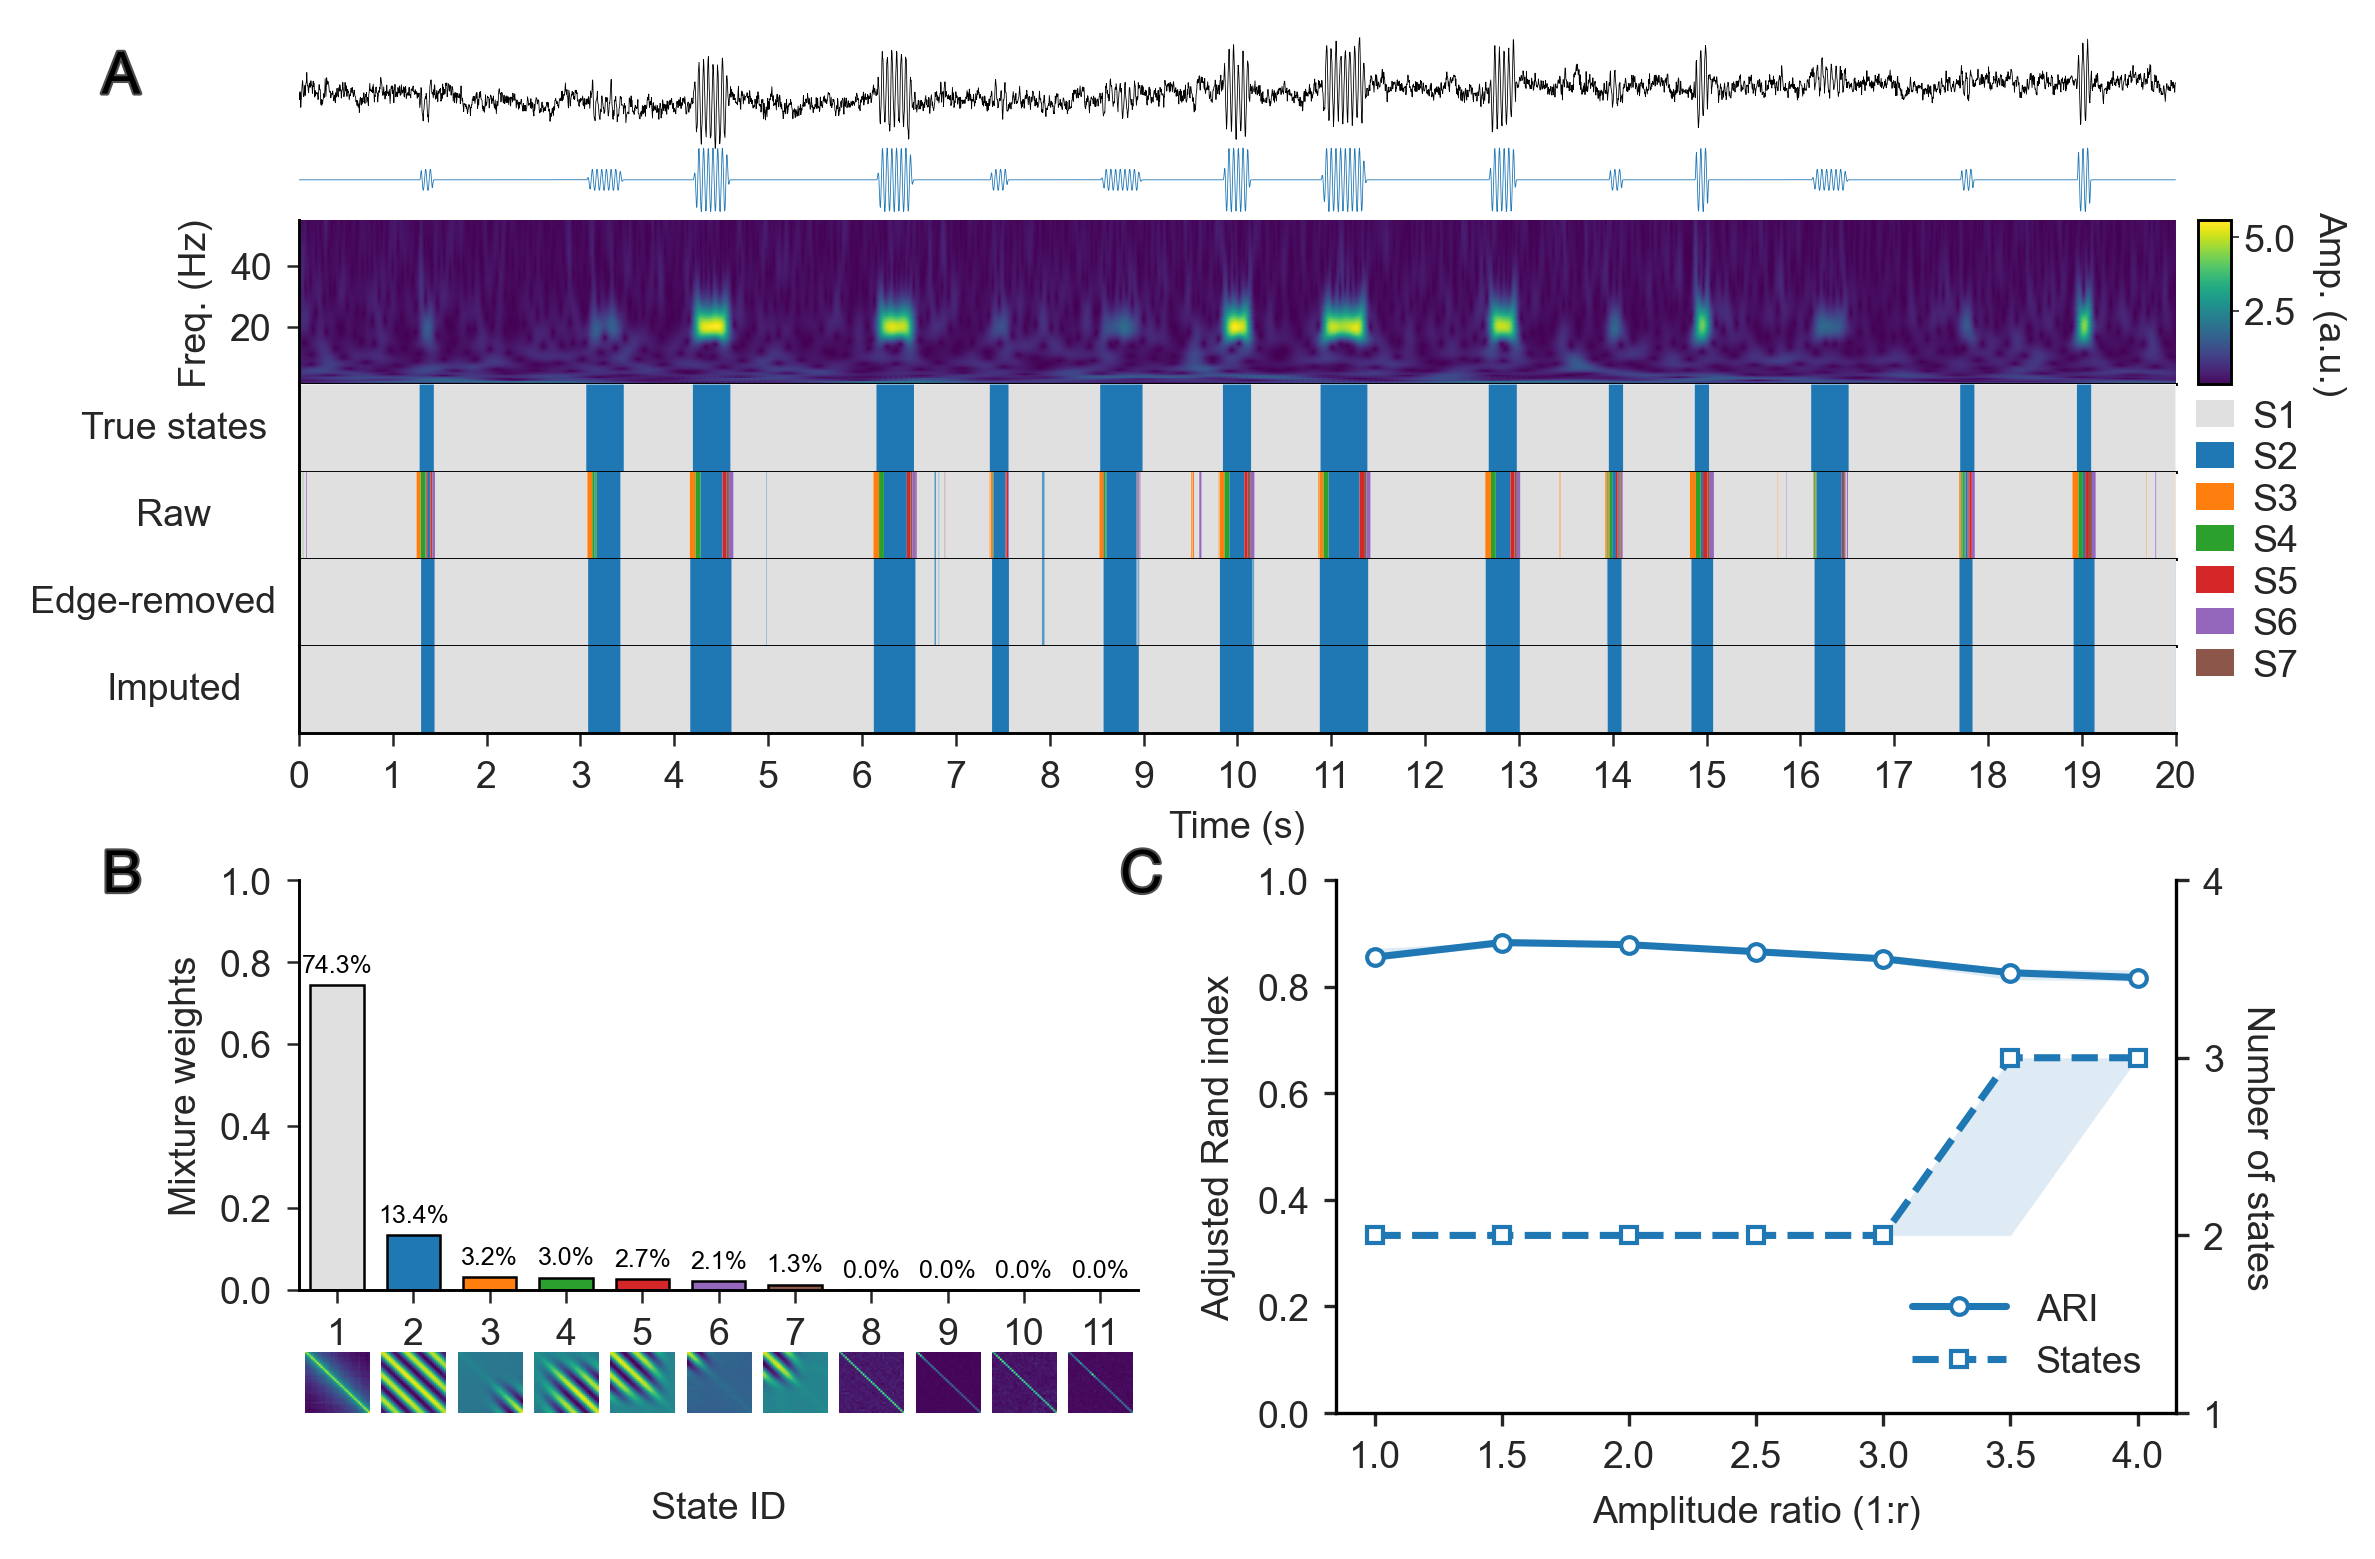

In [28]:
# Notebook plotting cell: uses your existing simulation variables and df.
# Run the updated plot_metrics_states helper definition before this cell.
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

plot_t = 20
n_plot = int(round(plot_t * fs))

n_true_states = int(np.nanmax(trimmed_states)) + 1
n_raw_states = len(untrunc_weights_raw)

n_total_states = max(n_true_states, n_raw_states, num_states_raw)

cmap = plt.get_cmap("tab10")

colors = ["#E0E0E0"] + [cmap(i % 10) for i in range(n_total_states - 1)]
state_labels = [f"S{i}" for i in range(n_total_states)]

# One-hot true states
trimmed_states_onehot = np.eye(n_total_states)[trimmed_states.astype(int)]

# Wavelet
t, f, amp = compute_wavelet(
    trimmed_signal[:n_plot],
    fs,
    f_min=1,
    f_max=80,
    df=0.5,
    wavelet="cmor1.5-1.0",
)

# median and across samples

metric = "ari"  # Choose "mcc", "ari", or "kappa".
metric = metric.strip().lower()
if metric not in {"mcc", "ari", "kappa"}:
    raise ValueError("metric must be 'mcc', 'ari', or 'kappa'.")

metric_ylim = (0, 1)  # Use (-1, 1) to include negative scores.
condition_label = "amp_ratio"

df_show = df.query(
    'method == "DP-GMM (Imputed & Edge-removed)"'
).copy()

df_plot = (
    df_show.groupby(condition_label)
    .agg(**{
        f"{metric}_median": (metric, "median"),
        f"{metric}_q25": (metric, lambda x: x.quantile(0.25)),
        f"{metric}_q75": (metric, lambda x: x.quantile(0.75)),
        "states_median": ("num_active_states", "median"),
        "states_q25": (
            "num_active_states",
            lambda x: x.quantile(0.25, interpolation="nearest"),
        ),
        "states_q75": (
            "num_active_states",
            lambda x: x.quantile(0.75, interpolation="nearest"),
        ),
    })
    .reset_index()
    .sort_values(condition_label)
)

x_ratio = df_plot[condition_label].to_numpy()

mosaic = [
    ["a1", "a1", "."],
    ["a2", "a2", "cbar1"],
    ["a3", "a3", "leg"],
    ["a4", "a4", "leg"],
    ["a5", "a5", "leg"],
    ["a6", "a6", "leg"],
    ["gap", "gap", "."],
    ["b", "c", "."],
    ["d", "c", "."],
]

fig, axes = plt.subplot_mosaic(
    mosaic,
    figsize=(FIG_WIDTH + 0.5, 5),
    constrained_layout=True,
    gridspec_kw={
        "height_ratios": [0.7, 0.6, 0.15, 0.15, 0.15, 0.15, 0.08, 1.5, 0.225],
        "width_ratios": [1, 1, 0.04],
    },
)

fig.set_constrained_layout_pads(
    w_pad=0.0,
    h_pad=0.0,
    wspace=0.01,
    hspace=0.001,
)

axes["gap"].axis("off")

#############
# simulated signal example
############

time_plot = trimmed_time_vec[:n_plot]

axes["a1"].plot(
    time_plot,
    1.5 * trimmed_signal[:n_plot],
    lw=0.2,
    color="k",
)

axes["a1"].grid(False)
axes["a1"].set_frame_on(False)

scale_burst = 1.3

for state_id in range(1, min(n_true_states, 4)):
    axes["a1"].plot(
        time_plot,
        -10 - state_id
        + scale_burst * (
                trimmed_bursts[:n_plot]
                * (trimmed_states[:n_plot] == state_id)
        ),
        lw=0.2,
        color=colors[state_id],
    )

axes["a1"].tick_params(
    axis="both",
    which="both",
    bottom=False,
    top=False,
    left=False,
    right=False,
    labelbottom=False,
    labelleft=False,
)

#########
# wavelet
#########

im = axes["a2"].imshow(
    amp,
    extent=[t[0], t[-1], f[0], f[-1]],
    origin="lower",
    aspect="auto",
    cmap="viridis",
    vmin=np.nanmin(amp),
    vmax=np.nanmax(amp),
)

axes["a2"].tick_params(
    axis="x",
    which="both",
    bottom=False,
    top=False,
    labelbottom=False,
    labeltop=False,
)
axes["a2"].yaxis.set_major_locator(MultipleLocator(20))
axes["a2"].set_ylim(1, 55)
axes["a2"].set_ylabel("Freq. (Hz)")

cb = fig.colorbar(im, cax=axes["cbar1"])
cb.set_label("Amp. (a.u.)", rotation=270, labelpad=12)
cb.ax.tick_params(which="both", length=2, width=0.4, pad=1)

# Robust SVG/PDF colorbar rendering
if hasattr(cb, "solids") and cb.solids is not None:
    cb.solids.set_edgecolor("face")
    cb.solids.set_rasterized(True)

##########
# true and estimated states
#########
axes["a3"].stackplot(
    time_plot,
    trimmed_states_onehot[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:n_total_states],
)
axes["a3"].set_ylabel("True states", rotation=0, labelpad=30, va="center")

axes["a4"].stackplot(
    time_plot,
    est_states_onehot_raw[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:est_states_onehot_raw.shape[1]],
    labels=[f"S{i + 1}" for i in range(est_states_onehot_raw.shape[1])],
)
axes["a4"].set_ylabel("Raw", rotation=0, labelpad=30, va="center")

axes["a5"].stackplot(
    time_plot,
    est_states_onehot_no_edge[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:est_states_onehot_no_edge.shape[1]],
)
axes["a5"].set_ylabel("Edge-removed", rotation=0, labelpad=35, va="center")

axes["a6"].stackplot(
    time_plot,
    est_states_onehot_no_edge_imputed[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:est_states_onehot_no_edge_imputed.shape[1]],
)
axes["a6"].set_ylabel(
    "Imputed",
    rotation=0,
    labelpad=30,
    va="center",
)

for key in ["a1", "a2", "a3", "a4", "a5", "a6"]:
    axes[key].sharex(axes["a1"])

for key in ["a3", "a4", "a5"]:
    axes[key].tick_params(
        axis="x",
        which="both",
        bottom=True,
        labelbottom=False,
        length=0,
    )
    axes[key].tick_params(
        axis="y",
        which="both",
        left=False,
        labelleft=False,
    )
    axes[key].set_yticks([])
    axes[key].set_xticks([])
    axes[key].set_ylim(0, 1)
    axes[key].set_xlim(0, plot_t)
    axes[key].spines["bottom"].set_visible(True)

axes["a6"].set_xlabel("Time (s)")
axes["a6"].xaxis.set_major_locator(MultipleLocator(1.0))
axes["a6"].tick_params(axis="y", which="both", left=False, labelleft=False)
axes["a6"].set_yticks([])
axes["a6"].set_ylim(0, 1)
axes["a6"].set_xlim(0, plot_t)
axes["a6"].spines["bottom"].set_visible(True)

##########
# Legend
#########
handles, labels = axes["a4"].get_legend_handles_labels()

axes["leg"].axis("off")
state_legend = axes["leg"].legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(-3, 0.55),
    bbox_transform=axes["leg"].transAxes,
    frameon=False,
    handlelength=1,
    handletextpad=0.5,
    labelspacing=0.2,
    borderaxespad=0.0,
    ncol=1,
    columnspacing=0.4,
)

state_legend.set_in_layout(False)

##########
# mixture weights
# #########

x_states = np.arange(n_raw_states)

axes["b"].bar(
    x_states,
    untrunc_weights_raw,
    width=0.7,
    color=colors[:n_raw_states],
    edgecolor="k",
    linewidth=0.6,
    zorder=2,
)

for k, w in enumerate(untrunc_weights_raw):
    axes["b"].text(
        k,
        w + 0.02,
        f"{w * 100.0:.1f}%",
        ha="center",
        va="bottom",
        color="k",
        fontsize=MY_FONT_SIZE - 3,
    )

axes["b"].set_ylabel("Mixture weights")
axes["b"].set_xticks(x_states, labels=np.arange(1, n_raw_states + 1))
axes["b"].set_ylim(0, 1)
axes["b"].set_xlim(-0.5, n_raw_states - 0.5)
axes["b"].tick_params(axis="y")


##########
# Selected metric and states across conditions
##########

ax_c, ax_c2 = plot_metrics_states(
    ax=axes["c"],
    df_plot=df_plot,
    x=x_ratio,
    metric=metric,
    mcc_ylim=metric_ylim,
    xlabel="Amplitude ratio (1:r)",
)

handles_metric, labels_metric = ax_c.get_legend_handles_labels()
handles_states, labels_states = ax_c2.get_legend_handles_labels()

ax_c2.legend(
    handles_metric + handles_states,
    labels_metric + labels_states,
    loc="lower right",
    frameon=False,
    fontsize=9,
    ncol=1,
    handlelength=2.5,
    columnspacing=0.8,
    labelcolor="0.15",
)

# ------------------------------------------------------------
# D: covariance thumbnails
# ------------------------------------------------------------

thumb_half_width = 0.42
thumb_y0 = -0.02
thumb_y1 = 0.8

axes["d"].set_xlim(-0.5, n_raw_states - 0.5)

for k in range(n_raw_states):
    im_dpgmm_cov = axes["d"].imshow(
        untrunc_covs_raw[k],
        extent=(
            k - thumb_half_width,
            k + thumb_half_width,
            thumb_y0,
            thumb_y1,
        ),
        cmap="viridis",
        origin="upper",
        aspect="auto",
    )
    im_dpgmm_cov.set_rasterized(True)

axes["d"].set_xlabel("State ID")
axes["d"].set_xlim(-0.5, n_raw_states - 0.5)
axes["d"].set_ylim(thumb_y0, thumb_y1)
axes["d"].set_xticks([])
axes["d"].set_yticks([])

for spine in axes["d"].spines.values():
    spine.set_visible(False)

fig.align_xlabels([axes["c"], axes["d"]])

fig.canvas.draw()
fig.set_constrained_layout(False)

state_keys = ["a3", "a4", "a5", "a6"]

pos = [axes[k].get_position() for k in state_keys]

x0 = min(p.x0 for p in pos)
x1 = max(p.x1 for p in pos)
y_top = max(p.y1 for p in pos)
y_bottom = min(p.y0 for p in pos)

n_rows = len(state_keys)
gap = 0.0
total_h = y_top - y_bottom
row_h = (total_h - gap * (n_rows - 1)) / n_rows

y1 = y_top

for key in state_keys:
    y0 = y1 - row_h
    axes[key].set_position([x0, y0, x1 - x0, row_h])
    y1 = y0 - gap

wavelet_cbar_left_shift = 0.014

pos_cbar1 = axes["cbar1"].get_position()
axes["cbar1"].set_position([
    pos_cbar1.x0 - wavelet_cbar_left_shift,
    pos_cbar1.y0,
    pos_cbar1.width,
    pos_cbar1.height,
])

###########
# panel label
###########

import matplotlib.patheffects as pe
from matplotlib.font_manager import FontProperties

# Finalize constrained_layout positions before reading axes positions
fig.canvas.draw()
fig.set_constrained_layout(False)

panel_font = FontProperties(
    family="Helvetica Neue",
    weight="heavy",
    size=14,
)

label_kw = dict(
    fontproperties=panel_font,
    color="k",
    ha="left",
    va="top",
    path_effects=[
        pe.withStroke(linewidth=1, foreground="0.30")
    ],
)

# Get axes positions in figure coordinates
pos_a = axes["a1"].get_position()
pos_b = axes["b"].get_position()
pos_c = axes["c"].get_position()

# A and B aligned to the same absolute figure x-position
x_left = 0.03

fig.text(
    x_left,
    min(pos_a.y1 + 0.035, 0.985),
    "A",
    transform=fig.transFigure,
    **label_kw,
)

fig.text(
    x_left,
    pos_b.y1 + 0.020,
    "B",
    transform=fig.transFigure,
    **label_kw,
)

fig.text(
    pos_c.x0 - 0.09,
    pos_c.y1 + 0.020,
    "C",
    transform=fig.transFigure,
    **label_kw,
)

#fig.suptitle(f"Amplitude ratio = 1:{amp_ratio}", fontsize=13, fontweight="bold", y=1.03)

# Shift colorbar slightly to the left
fig.canvas.draw()

pos = axes["cbar1"].get_position()
axes["cbar1"].set_position([
    pos.x0 - 0.021,  # Shift left
    pos.y0,
    pos.width,
    pos.height,
])


save_path = fig_dir / f"within_state_amplitude_ratio_{amp_ratio:g}_{metric}"

for fmt in ["svg", "pdf"]:
    fig.savefig(
        save_path.with_suffix(f".{fmt}"),
        format=fmt,
        bbox_inches="tight",
        pad_inches=0.1,
        dpi=900,
    )


print(f"Figure saved to: {save_path}")

plt.show()

# Nonsinusoidal waves

In [51]:
sim_cond = "waveform_asymmetry_snr"

fig_dir = Path("../figures") / str(sim_cond)
fig_dir.mkdir(parents=True, exist_ok=True)


# Condition 1: burst morphologies
burst_types = ["sine", "asine"]

# Condition 2: Signal-to-noise ratio (in dB)
snr_range = np.arange(-10, 11, 2)  # varying SNRs from -10 to 10 dB

signal_dir = "../data/simulations"
sim_data = np.load(f'{signal_dir}/{sim_cond}_data.npz')

#load the simulated data
signal_sample = sim_data['signal_sample']
states_sample = sim_data['states_sample']
bursts_sample = sim_data['bursts_sample']

print("shape of signal_sample", signal_sample.shape)

performance_dir = "../data/performance"
file_path = f"{performance_dir}/results_{sim_cond}.pkl"

import pickle

with open(file_path, "rb") as f:
    res = pickle.load(f)

df_list = [pd.DataFrame(r) for r in res]
df = pd.concat(df_list, axis=0, ignore_index=True)

df["burst_f"] = df["burst_f"].apply(tuple)

df["num_active_states"] = df["est_params"].apply(
    lambda x: x.get("num_active_states", np.nan)
    if isinstance(x, dict) else np.nan
)

df.head()

shape of signal_sample (20, 2, 11, 45000)


,sample_id,signal,true_states,burst_f,fs,burst_type,snr,est_params,loss_best,model_id_best,...,matched_est_states,state_labels,order,summary_stats,mcc,ari,kappa,loss,method,num_active_states
0,0,"[-0.5404168239386009, -0.8063092548745979, -1....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,sine,-10,"{'alpha': 0.38761258, 'weights': [1.0], 'means...",0.777863,3,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",[0],[0],None,0.0,0.0,0.0,0.777863,DP-GMM,1
1,0,"[-0.5404168239386009, -0.8063092548745979, -1....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,sine,-10,"{'alpha': 0.38761258, 'weights': [1.0], 'means...",0.777863,3,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",[0],[0],None,0.0,0.0,0.0,0.777863,DP-GMM (Edge-removed),1
2,0,"[-0.5404168239386009, -0.8063092548745979, -1....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,sine,-10,"{'alpha': 0.38761258, 'weights': [1.0], 'means...",0.777863,3,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",[0],[0],None,0.0,0.0,0.0,0.777863,DP-GMM (Imputed),1
3,0,"[-0.5404168239386009, -0.8063092548745979, -1....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,sine,-10,"{'alpha': 0.38761258, 'weights': [1.0], 'means...",0.777863,3,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",[0],[0],None,0.0,0.0,0.0,0.777863,DP-GMM (Imputed & Edge-removed),1
4,0,"[-0.5387468215470379, -0.8037990009456715, -1....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,sine,-8,"{'alpha': 0.39277655, 'weights': [1.0], 'means...",0.778796,3,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",[0],[0],None,0.0,0.0,0.0,0.778796,DP-GMM,1


Figure saved to: /Users/yamadashoto/Library/Mobile Documents/com~apple~CloudDocs/PhD German/project/TDE-DP-GMM/figures/waveform_asymmetry_snr/mean_psd_by_waveform


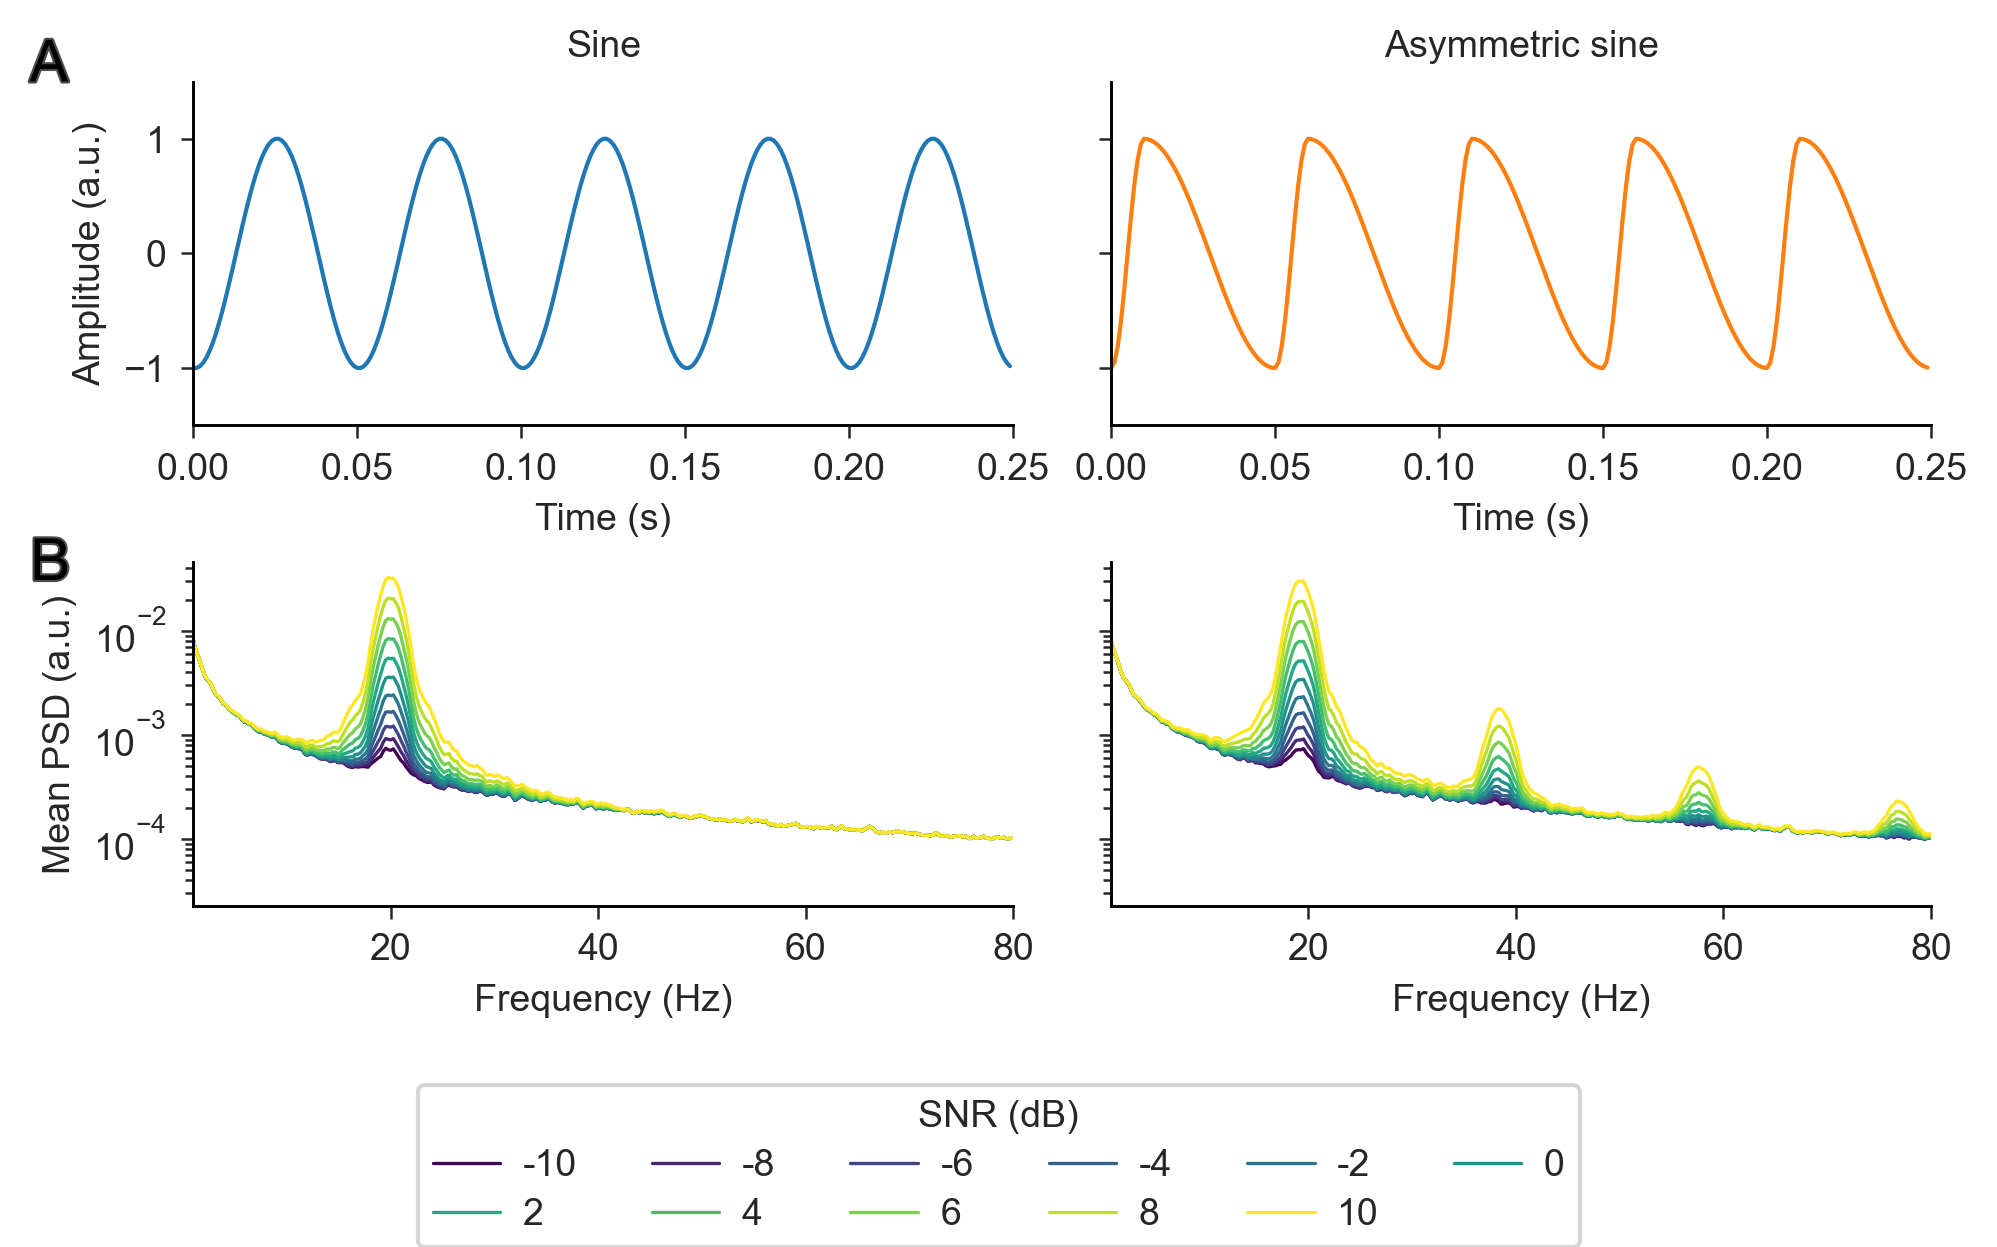

In [54]:
"""Plot waveform examples above simulation-averaged PSDs in a 2 × 2 grid.

Run after loading:
    signal_sample, burst_types, snr_range,
    FIG_WIDTH, MY_FONT_SIZE, fig_dir

signal_sample shape:
    (samples, waveform types, SNRs, time)
"""

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import Normalize
from matplotlib.font_manager import FontProperties
from matplotlib.ticker import MultipleLocator
from neurodsp.sim import sim_oscillation
from scipy.signal import welch


# Sampling and waveform settings.
data_fs = 250
waveform_fs = 1000
waveform_freq = 20.0
waveform_duration = 5 / waveform_freq

asine_rise_ratio = 0.2

cycles = ["sine", "asine"]
titles = ["Sine", "Asymmetric sine"]

cycle_params = {
    "sine": {},
    "asine": {"rdsym": asine_rise_ratio},
}


# Validate the simulation data.
signals = np.asarray(signal_sample)
snr_values = np.asarray(snr_range, dtype=float)
waveform_names = [str(name).lower() for name in burst_types]

if signals.ndim != 4:
    raise ValueError(
        "signal_sample must have shape "
        "(samples, waveform types, SNRs, time)."
    )

if (
    snr_values.ndim != 1
    or snr_values.size == 0
    or not np.isfinite(snr_values).all()
):
    raise ValueError(
        "snr_range must be a nonempty, finite one-dimensional array."
    )

if signals.shape[1:3] != (len(waveform_names), len(snr_values)):
    raise ValueError(
        "signal_sample dimensions do not match burst_types and snr_range."
    )

if signals.shape[0] == 0 or signals.shape[-1] < 2:
    raise ValueError(
        "At least one simulation and two time samples are required."
    )

if any(waveform_names.count(cycle) != 1 for cycle in cycles):
    raise ValueError(
        "burst_types must contain sine and asine exactly once."
    )

# Match waveform conditions by name.
waveform_indices = [
    waveform_names.index(cycle) for cycle in cycles
]


# Compute PSDs from the simulation data.
psd_nperseg = min(1024, signals.shape[-1])

freqs_psd, psds = welch(
    signals,
    fs=data_fs,
    window="hann",
    nperseg=psd_nperseg,
    noverlap=psd_nperseg // 2,
    scaling="density",
    axis=-1,
)

# Average across simulations.
# Shape: (waveform types, SNRs, frequencies).
mean_psds = psds.mean(axis=0)

snr_min = snr_values.min()
snr_max = snr_values.max()

if snr_min == snr_max:
    snr_min -= 0.5
    snr_max += 0.5

norm = Normalize(vmin=snr_min, vmax=snr_max)
cmap = plt.get_cmap("viridis")


# Figure: waveform examples above their simulation PSDs.
fig, axes = plt.subplots(
    2, 2,
    figsize=(FIG_WIDTH-1, 4),
    sharex="row",
    sharey="row",
    constrained_layout=True,
)

example_waveforms = {}

for col, cycle in enumerate(cycles):
    waveform = sim_oscillation(
        n_seconds=waveform_duration,
        fs=waveform_fs,
        freq=waveform_freq,
        cycle=cycle,
        phase="min",
        **cycle_params[cycle],
    )

    # Center and peak-normalize only the illustrative waveform.
    waveform = waveform - waveform.mean()
    peak_amplitude = np.max(np.abs(waveform))

    if not np.isfinite(peak_amplitude) or peak_amplitude == 0:
        raise ValueError(
            f"Cannot peak-normalize the {cycle} example."
        )

    waveform = waveform / peak_amplitude
    example_waveforms[cycle] = waveform
    waveform_time = np.arange(len(waveform)) / waveform_fs

    # Top row: show three oscillation periods.
    waveform_ax = axes[0, col]
    waveform_ax.plot(
        waveform_time,
        waveform,
        color=f"C{col}",
        linewidth=1.0,
    )
    waveform_ax.set_title(titles[col])
    waveform_ax.set_xlim(0, waveform_duration)
    waveform_ax.xaxis.set_major_locator(
        MultipleLocator(1 / waveform_freq)
    )
    waveform_ax.set_xlabel("Time (s)")
    waveform_ax.margins(y=0.25)

    # Bottom row: mean simulation PSD at each SNR.
    psd_ax = axes[1, col]
    waveform_index = waveform_indices[col]

    for snr_id, snr_db in enumerate(snr_values):
        psd_ax.plot(
            freqs_psd,
            mean_psds[waveform_index, snr_id],
            color=cmap(norm(snr_db)),
            linewidth=0.8,
            label=f"{snr_db:g}",
        )

    psd_ax.set_yscale("log", nonpositive="mask")
    psd_ax.set_xlim(1, min(80, data_fs / 2))
    psd_ax.set_xlabel("Frequency (Hz)")

axes[0, 0].set_ylabel("Amplitude (a.u.)")
axes[1, 0].set_ylabel(r"Mean PSD (a.u.)")


# Shared SNR legend below panel B.
legend_style = dict(
    frameon=True,
    fontsize=MY_FONT_SIZE,
    title_fontsize=MY_FONT_SIZE,
    handlelength=1.8,
    handletextpad=0.6,
    labelspacing=0.4,
    borderaxespad=0,
)

handles, labels = axes[1, 0].get_legend_handles_labels()

# Sort SNR values and arrange them in ascending order across rows.
n_columns = min(6, len(snr_values))
order = np.argsort(snr_values)
order = np.concatenate([
    order[col::n_columns] for col in range(n_columns)
])

fig.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    title="SNR (dB)",
    loc="outside lower center",
    ncol=n_columns,
    **legend_style,
)


# Finalize and freeze the layout before adding panel labels.
fig.canvas.draw()
fig.set_layout_engine("none")

panel_font = FontProperties(
    family="Helvetica Neue",
    weight="heavy",
    size=14,
)

label_kw = dict(
    fontproperties=panel_font,
    color="k",
    ha="left",
    va="top",
    path_effects=[
        pe.withStroke(linewidth=1, foreground="0.30")
    ],
)

pos_a = axes[0, 0].get_position()
pos_b = axes[1, 0].get_position()
x_left = 0.0

fig.text(
    x_left,
    min(pos_a.y1 + 0.035, 0.985),
    "A",
    transform=fig.transFigure,
    **label_kw,
)

fig.text(
    x_left,
    pos_b.y1 + 0.020,
    "B",
    transform=fig.transFigure,
    **label_kw,
)


# Save the combined figure.
fig_dir = Path(fig_dir)
fig_dir.mkdir(parents=True, exist_ok=True)
save_path = fig_dir / "mean_psd_by_waveform"

for fmt in ("svg", "pdf"):
    fig.savefig(
        save_path.with_suffix(f".{fmt}"),
        format=fmt,
        bbox_inches="tight",
        pad_inches=0.1,
        dpi=900,
    )

print(f"Figure saved to: {save_path.resolve()}")

plt.show()

In [55]:

# Compute median and quartiles
median_df = (
    df
    .groupby(["burst_type", "snr", "method"])
    .agg(
        mcc_median=("mcc", "median"),
        mcc_q25=("mcc", lambda x: x.quantile(0.25)),
        mcc_q75=("mcc", lambda x: x.quantile(0.75)),

        num_active_states_median=("num_active_states", "median"),
        num_active_states_q25=("num_active_states", lambda x: x.quantile(0.25)),
        num_active_states_q75=("num_active_states", lambda x: x.quantile(0.75)),

    )
    .reset_index()
)

median_df

,burst_type,snr,method,mcc_median,mcc_q25,mcc_q75,num_active_states_median,num_active_states_q25,num_active_states_q75
0,asine,-10,DP-GMM,0.000000,0.000000,0.000000,1.0,1.0,1.0
1,asine,-10,DP-GMM (Edge-removed),0.000000,0.000000,0.000000,1.0,1.0,1.0
2,asine,-10,DP-GMM (Imputed & Edge-removed),0.000000,0.000000,0.000000,1.0,1.0,1.0
3,asine,-10,DP-GMM (Imputed),0.000000,0.000000,0.000000,1.0,1.0,1.0
4,asine,-8,DP-GMM,0.000000,0.000000,0.000000,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...
83,sine,8,DP-GMM (Imputed),0.752102,0.742185,0.760118,6.0,6.0,7.0
84,sine,10,DP-GMM,0.648372,0.646393,0.654404,6.5,6.0,7.0
85,sine,10,DP-GMM (Edge-removed),0.910662,0.905372,0.913167,2.0,2.0,2.0
86,sine,10,DP-GMM (Imputed & Edge-removed),0.915062,0.910320,0.917658,2.0,2.0,2.0


In [56]:
sample_id = 0
snr = 2
burst_type = "sine"
fs = 250

# Raw DP-GMM
df_raw = df.query(
    "method == 'DP-GMM' & sample_id == @sample_id & burst_type == @burst_type & snr == @snr"
).iloc[0]

df_raw

sample_id                                                             0
signal                [-0.5014190371155979, -0.747924996548991, -1.7...
true_states           [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
burst_f                                                           (20,)
fs                                                                  250
burst_type                                                         sine
snr                                                                   2
est_params            {'alpha': 0.430773, 'weights': [0.6937621, 0.3...
loss_best                                                      0.744022
model_id_best                                                         5
seed_best                                                    2666256175
loss_all              [[1.4681191, 1.2395513, 1.1557614, 1.0882322, ...
fit_t                                                        238.860791
pred_t                                                         0

In [60]:

from nds_toolbox.preprocessing.features import compute_wavelet
from nds_toolbox.preprocessing.features import trim_data

#df_list = [pd.DataFrame(r) for r in res]

#df = pd.concat(df_list, axis = 0, ignore_index = True)

#df["burst_f"] = df["burst_f"].apply(tuple)


# extract parameters

sample_id = 0

cond1_id = 1
burst_type = burst_types[cond1_id]

print(burst_type)
snr = 2
cond2_id = np.where(snr_range == snr)[0][0]

fs = 250

# Raw DP-GMM
df_raw = df.query(
    "method == 'DP-GMM' & sample_id == @sample_id & burst_type == @burst_type & snr == @snr"
).iloc[0]

#common across variants

signal = signal_sample[sample_id, cond1_id, cond2_id]
bursts = bursts_sample[sample_id, cond1_id, cond2_id]
true_states = states_sample[sample_id, cond1_id, cond2_id].astype(int)

num_emb = df_raw["num_emb"]
trimmed_signal = trim_data(signal, num_emb, verbose=False)
trimmed_bursts = trim_data(bursts, num_emb, verbose=False)
trimmed_states = trim_data(true_states, num_emb, verbose=False)
num_states_true = int(trimmed_states.max() + 1)
true_states_onehot = np.eye(num_states_true)[trimmed_states]

trimmed_time_vec = np.arange(len(trimmed_states)) / fs

#raw dpgmm results

mcc_raw = df_raw["mcc"]
ari_raw = df_raw["ari"]
kappa_raw = df_raw["kappa"]

num_states = df_raw["num_states"]

est_params_raw = df_raw["est_params"]
weights_raw = est_params_raw["weights"]
means_raw = est_params_raw["means"]
covs_raw = est_params_raw["covs"]
alpha_raw = est_params_raw["alpha"]

num_states_raw = len(weights_raw)
est_states_raw = df_raw["est_states"]
est_states_onehot_raw = np.eye(num_states_raw)[est_states_raw]

untrunc_weights_raw = est_params_raw["untrunc_weights"]
untrunc_means_raw = est_params_raw["untrunc_means"]
untrunc_covs_raw = est_params_raw["untrunc_covs"]

#dpgmm with edge removal

df_no_edge = df.query(
    "method == 'DP-GMM (Edge-removed)' & sample_id == @sample_id & burst_type == @burst_type & snr == @snr"
).iloc[0]

num_states_no_edge = df_no_edge["num_states"]
est_states_no_edge = df_no_edge["est_states"]
est_states_onehot_no_edge = np.eye(num_states_no_edge)[est_states_no_edge]


mcc_no_edge = df_no_edge["mcc"]
ari_no_edge = df_no_edge["ari"]
kappa_no_edge = df_no_edge["kappa"]


#dpgmm with edge removal and imputation

df_no_edge_imputed = df.query(
    "method == 'DP-GMM (Imputed & Edge-removed)' & sample_id == @sample_id & burst_type == @burst_type & snr == @snr"
).iloc[0]
num_states_no_edge_imputed = df_no_edge_imputed["num_states"]
est_states_no_edge_imputed = df_no_edge_imputed["est_states"]

est_states_onehot_no_edge_imputed = np.eye(num_states_no_edge_imputed)[est_states_no_edge_imputed]

mcc_no_edge_imputed = df_no_edge_imputed["mcc"]
ari_no_edge_imputed = df_no_edge_imputed["ari"]
kappa_no_edge_imputed = df_no_edge_imputed["kappa"]



print("upper bound:", num_states)
print("active states:", num_states_raw)
print("active states (no edges):", num_states_no_edge)
print("true states:", num_states_true)

print("MCC (raw):", mcc_raw)
print("MCC (without edge):", mcc_no_edge)
print("MCC (without edge & imputed):", mcc_no_edge_imputed)

print()
print("ARI (raw):", ari_raw)
print("ARI (without edge):", ari_no_edge)
print("ARI (without edge & imputed):", ari_no_edge_imputed)

print()
print("Kappa (raw):", kappa_raw)
print("Kappa (without edge):", kappa_no_edge)
print("Kappa (with edge):", kappa_no_edge_imputed)




asine
upper bound: 11
active states: 3
active states (no edges): 11
true states: 2
MCC (raw): 0.8220546668880206
MCC (without edge): 0.8734130959089516
MCC (without edge & imputed): 0.9119955882511983

ARI (raw): 0.7939455467707494
ARI (without edge): 0.8078159205811476
ARI (without edge & imputed): 0.8597181449603258

Kappa (raw): 0.8196964592988774
Kappa (without edge): 0.871300066543379
Kappa (with edge): 0.9115915559561736


Figure saved to: ../figures/waveform_asymmetry_snr/asine_snr_2_ari


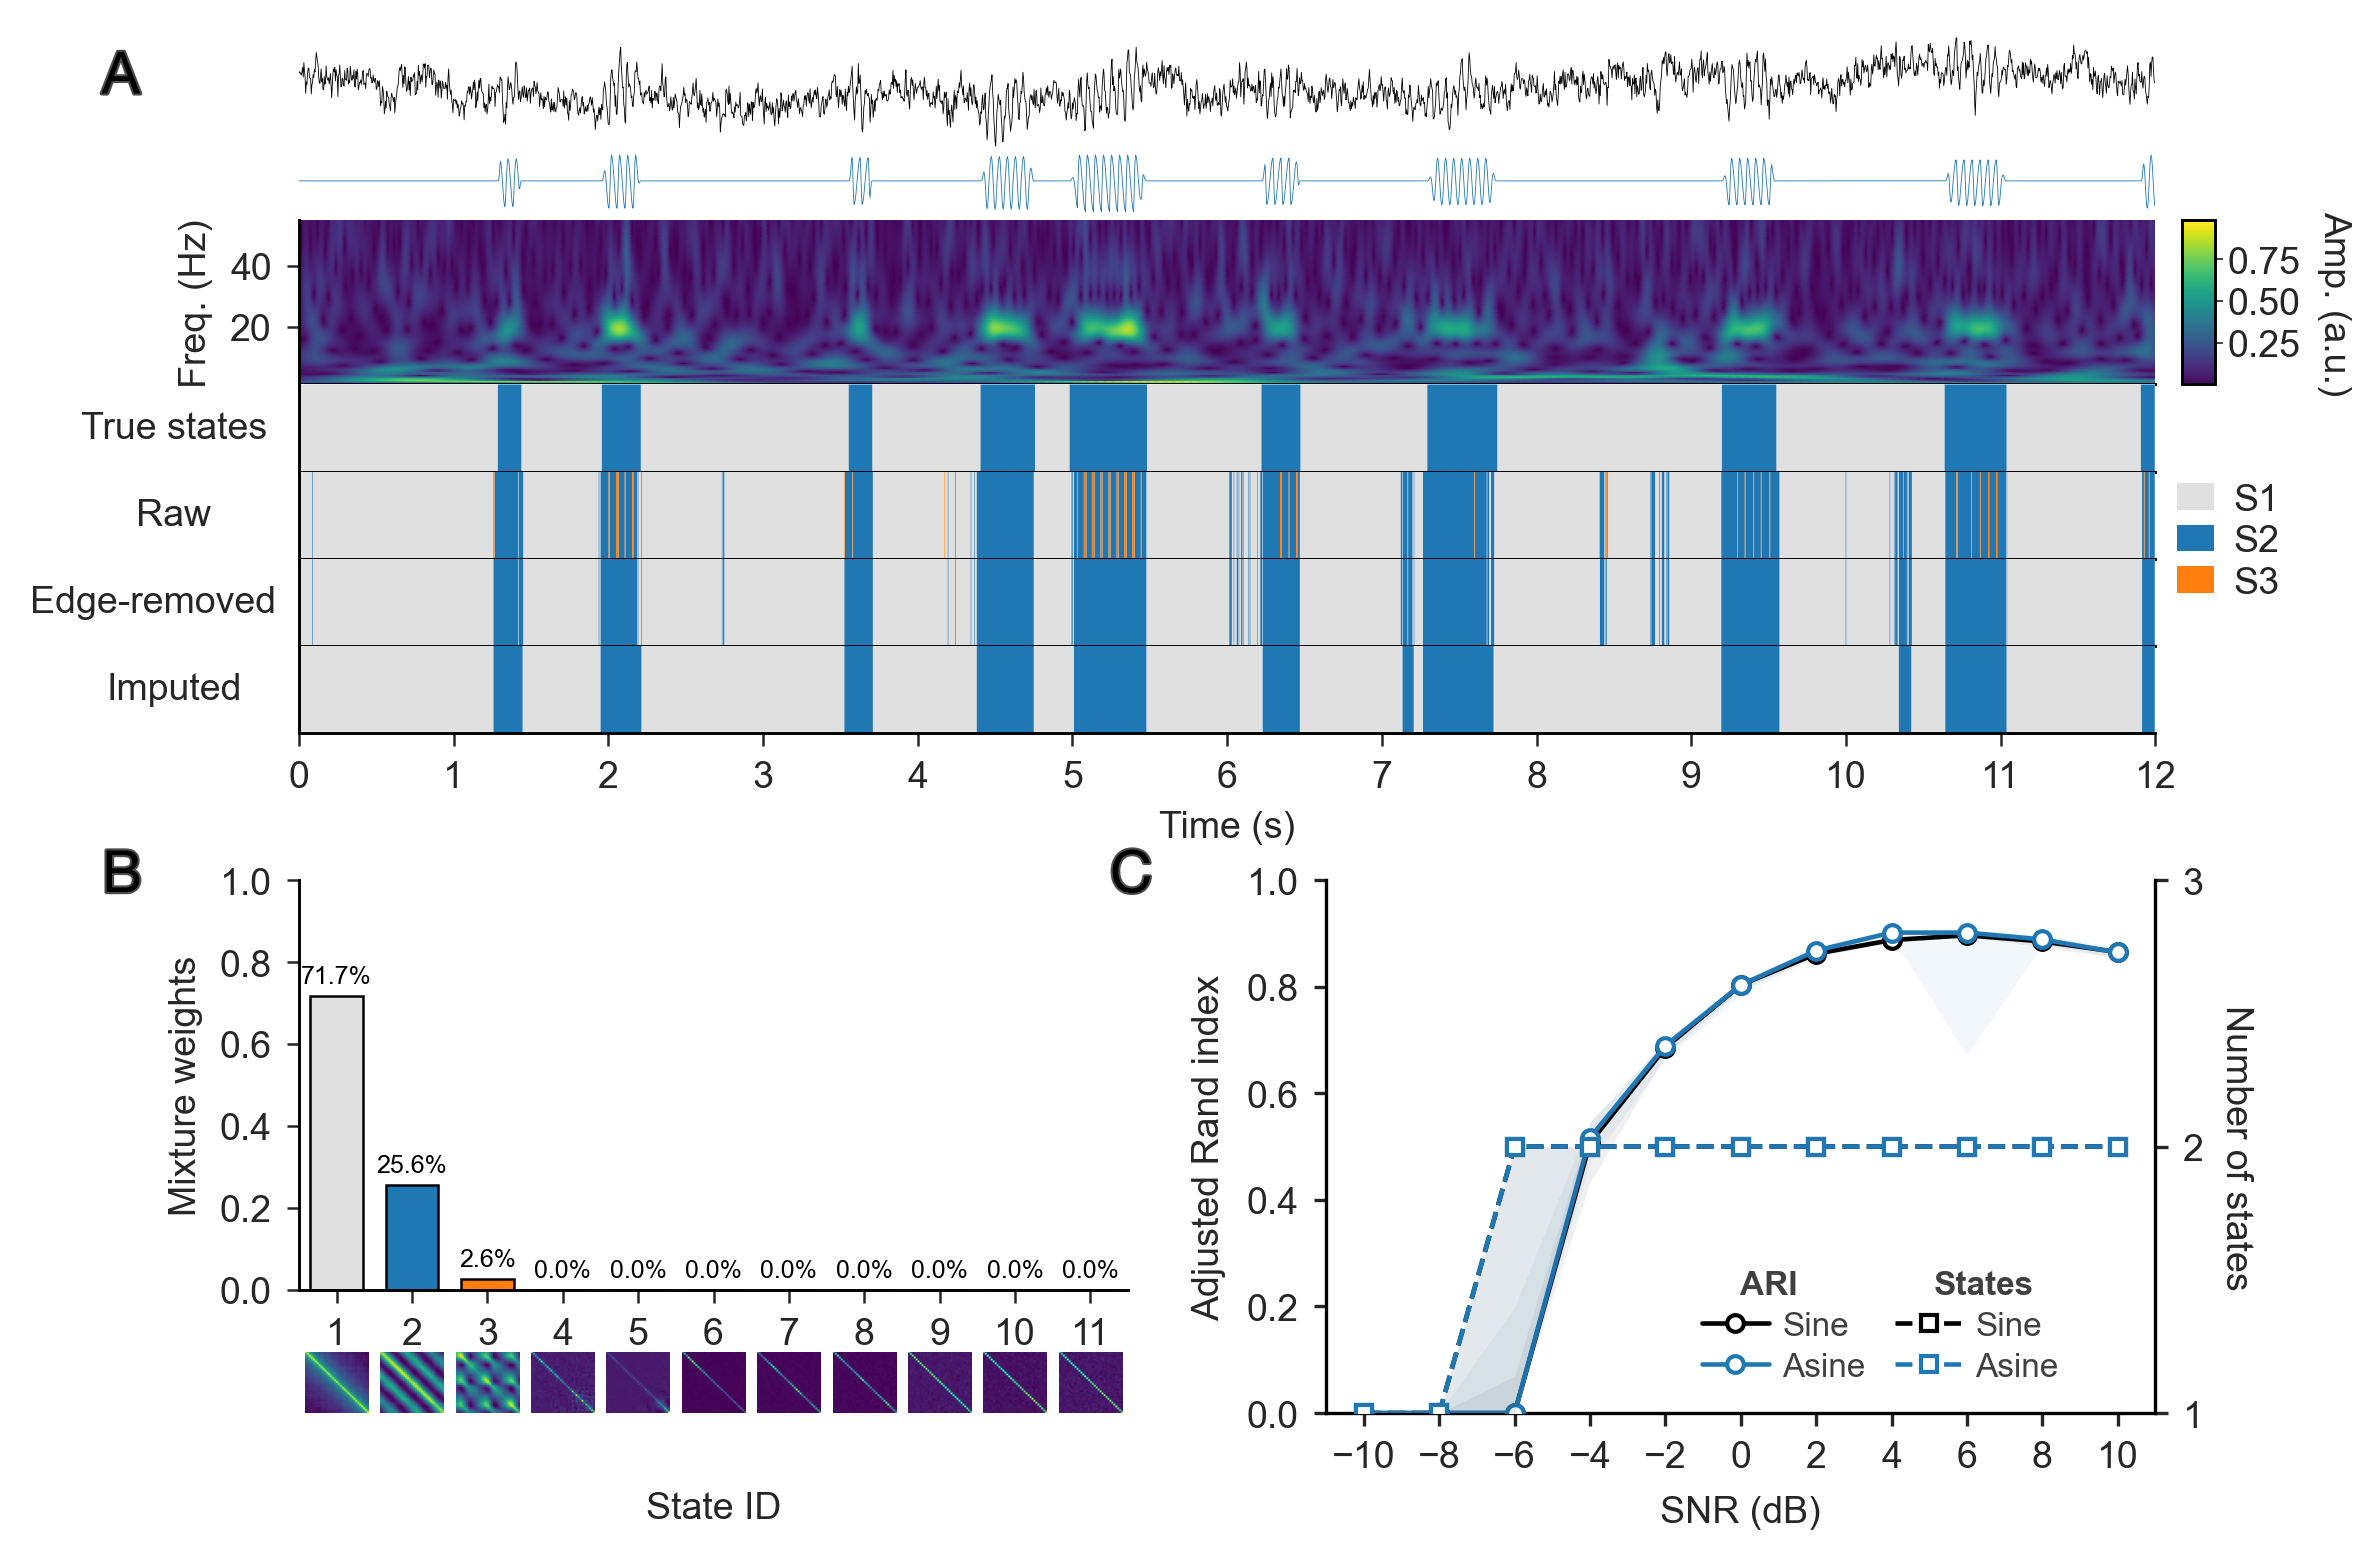

In [66]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

plot_t = 12
n_plot = int(round(plot_t * fs))

n_true_states = int(np.nanmax(trimmed_states)) + 1
n_raw_states = len(untrunc_weights_raw)

n_total_states = max(n_true_states, n_raw_states, num_states_raw)

cmap = plt.get_cmap("tab10")

colors = ["#E0E0E0"] + [cmap(i % 10) for i in range(n_total_states - 1)]
state_labels = [f"S{i}" for i in range(n_total_states)]

# One-hot true states
trimmed_states_onehot = np.eye(n_total_states)[trimmed_states.astype(int)]

# Wavelet
t, f, amp = compute_wavelet(
    trimmed_signal[:n_plot],
    fs,
    f_min=1,
    f_max=80,
    df=0.5,
    wavelet="cmor1.5-1.0",
)

# Selected metric and active-state counts across samples

metric = "ari"  # Choose "mcc", "ari", or "kappa".
metric = metric.strip().lower()
if metric not in {"mcc", "ari", "kappa"}:
    raise ValueError("metric must be 'mcc', 'ari', or 'kappa'.")

metric_ylim = (0, 1)  # Use (-1, 1) to include negative scores.
cond1_label = "burst_type"
cond2_label = "snr"

df_show = df.query(
    'method == "DP-GMM (Imputed & Edge-removed)"'
).copy()

df_plot = (
    df_show.groupby([cond1_label, cond2_label])
    .agg(**{
        f"{metric}_median": (metric, "median"),
        f"{metric}_q25": (metric, lambda x: x.quantile(0.25)),
        f"{metric}_q75": (metric, lambda x: x.quantile(0.75)),
        "states_median": ("num_active_states", "median"),
        "states_q25": (
            "num_active_states",
            lambda x: x.quantile(0.25, interpolation="nearest"),
        ),
        "states_q75": (
            "num_active_states",
            lambda x: x.quantile(0.75, interpolation="nearest"),
        ),
    })
    .reset_index()
    .sort_values([cond1_label, cond2_label])
)

mosaic = [
    ["a1", "a1", "."],
    ["a2", "a2", "cbar1"],
    ["a3", "a3", "leg"],
    ["a4", "a4", "leg"],
    ["a5", "a5", "leg"],
    ["a6", "a6", "leg"],
    ["gap", "gap", "."],
    ["b", "c", "."],
    ["d", "c", "."],
]

fig, axes = plt.subplot_mosaic(
    mosaic,
    figsize=(FIG_WIDTH + 0.5, 5),
    constrained_layout=True,
    gridspec_kw={
        "height_ratios": [0.7, 0.6, 0.15, 0.15, 0.15, 0.15, 0.08, 1.5, 0.225],
        "width_ratios": [1, 1, 0.04],
    },
)

fig.set_constrained_layout_pads(
    w_pad=0.0,
    h_pad=0.0,
    wspace=0.01,
    hspace=0.001,
)

axes["gap"].axis("off")

#############
# simulated signal example
############

time_plot = trimmed_time_vec[:n_plot]

axes["a1"].plot(
    time_plot,
    1.5 * trimmed_signal[:n_plot],
    lw=0.2,
    color="k",
)

axes["a1"].grid(False)
axes["a1"].set_frame_on(False)

scale_burst = 1.8

for state_id in range(1, min(n_true_states, 4)):
    axes["a1"].plot(
        time_plot,
        -2 - state_id
        + scale_burst * (
                trimmed_bursts[:n_plot]
                * (trimmed_states[:n_plot] == state_id)
        ),
        lw=0.2,
        color=colors[state_id],
    )

axes["a1"].tick_params(
    axis="both",
    which="both",
    bottom=False,
    top=False,
    left=False,
    right=False,
    labelbottom=False,
    labelleft=False,
)

#########
# wavelet
#########

im = axes["a2"].imshow(
    amp,
    extent=[t[0], t[-1], f[0], f[-1]],
    origin="lower",
    aspect="auto",
    cmap="viridis",
    vmin=np.nanmin(amp),
    vmax=np.nanmax(amp),
)

axes["a2"].tick_params(
    axis="x",
    which="both",
    bottom=False,
    top=False,
    labelbottom=False,
    labeltop=False,
)
axes["a2"].yaxis.set_major_locator(MultipleLocator(20))
axes["a2"].set_ylim(1, 55)
axes["a2"].set_ylabel("Freq. (Hz)")

cb = fig.colorbar(im, cax=axes["cbar1"])
cb.set_label("Amp. (a.u.)", rotation=270, labelpad=12)
cb.ax.tick_params(which="both", length=2, width=0.4, pad=1)

# Robust SVG/PDF colorbar rendering
if hasattr(cb, "solids") and cb.solids is not None:
    cb.solids.set_edgecolor("face")
    cb.solids.set_rasterized(True)

##########
# true and estimated states
#########
axes["a3"].stackplot(
    time_plot,
    trimmed_states_onehot[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:n_total_states],
)
axes["a3"].set_ylabel("True states", rotation=0, labelpad=30, va="center")

axes["a4"].stackplot(
    time_plot,
    est_states_onehot_raw[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:est_states_onehot_raw.shape[1]],
    labels=[f"S{i + 1}" for i in range(est_states_onehot_raw.shape[1])],
)
axes["a4"].set_ylabel("Raw", rotation=0, labelpad=30, va="center")

axes["a5"].stackplot(
    time_plot,
    est_states_onehot_no_edge[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:est_states_onehot_no_edge.shape[1]],
)
axes["a5"].set_ylabel("Edge-removed", rotation=0, labelpad=35, va="center")

axes["a6"].stackplot(
    time_plot,
    est_states_onehot_no_edge_imputed[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:est_states_onehot_no_edge_imputed.shape[1]],
)
axes["a6"].set_ylabel(
    "Imputed",
    rotation=0,
    labelpad=30,
    va="center",
)

for key in ["a1", "a2", "a3", "a4", "a5", "a6"]:
    axes[key].sharex(axes["a1"])

for key in ["a3", "a4", "a5"]:
    axes[key].tick_params(
        axis="x",
        which="both",
        bottom=True,
        labelbottom=False,
        length=0,
    )
    axes[key].tick_params(
        axis="y",
        which="both",
        left=False,
        labelleft=False,
    )
    axes[key].set_yticks([])
    axes[key].set_xticks([])
    axes[key].set_ylim(0, 1)
    axes[key].set_xlim(0, plot_t)
    axes[key].spines["bottom"].set_visible(True)

axes["a6"].set_xlabel("Time (s)")
axes["a6"].xaxis.set_major_locator(MultipleLocator(1.0))
axes["a6"].tick_params(axis="y", which="both", left=False, labelleft=False)
axes["a6"].set_yticks([])
axes["a6"].set_ylim(0, 1)
axes["a6"].set_xlim(0, plot_t)
axes["a6"].spines["bottom"].set_visible(True)

##########
# Legend
#########
handles, labels = axes["a4"].get_legend_handles_labels()

axes["leg"].axis("off")
state_legend = axes["leg"].legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(-3, 0.55),
    bbox_transform=axes["leg"].transAxes,
    frameon=False,
    handlelength=1,
    handletextpad=0.5,
    labelspacing=0.2,
    borderaxespad=0.0,
    ncol=1,
    columnspacing=0.4,
)

state_legend.set_in_layout(False)

##########
# mixture weights
# #########

x_states = np.arange(n_raw_states)

axes["b"].bar(
    x_states,
    untrunc_weights_raw,
    width=0.7,
    color=colors[:n_raw_states],
    edgecolor="k",
    linewidth=0.6,
    zorder=2,
)

for k, w in enumerate(untrunc_weights_raw):
    axes["b"].text(
        k,
        w + 0.02,
        f"{w * 100.0:.1f}%",
        ha="center",
        va="bottom",
        color="k",
        fontsize=MY_FONT_SIZE - 3,
    )

axes["b"].set_ylabel("Mixture weights")
axes["b"].set_xticks(x_states, labels=np.arange(1, n_raw_states + 1))
axes["b"].set_ylim(0, 1)
axes["b"].set_xlim(-0.5, n_raw_states - 0.5)
axes["b"].tick_params(axis="y")

##########
# Selected metric and states across conditions
#########


##########
# Selected metric and states across burst waveforms
##########

ax_c = axes["c"]
ax_c2 = None





for burst_type, condition_label, color in [
    ("sine", "Sine", "black"),
    ("asine", "Asine", "#1f77b4"),
]:
    ax_c, ax_c2 = plot_metrics_states(
        ax=ax_c,
        ax2=ax_c2,
        df_plot=df_plot[
            df_plot["burst_type"] == burst_type
        ].sort_values("snr"),
        x="snr",
        metric=metric,
        mcc_ylim=metric_ylim,
        xlabel="SNR (dB)",
        condition_label=condition_label,
        color_mcc=color,
        color_states=color,
        linestyle="-",
        linestyle_states="--",
        band_alpha=0.06,
        linewidth=1.1,
    )
# Combined legend: selected metric in the left column, states in the right
handles_metric, labels_metric = ax_c.get_legend_handles_labels()
handles_states, labels_states = ax_c2.get_legend_handles_labels()
from matplotlib.lines import Line2D

blank = Line2D([], [], linestyle="none")
names = ["Sine", "Asine"]
metric_title = {"ari": "ARI", "mcc": "MCC", "kappa": "Kappa"}[metric]

legend = ax_c2.legend(
    [blank, *handles_metric, blank, *handles_states],
    [metric_title, *names, "States", *names],
    loc="lower right",
    bbox_to_anchor=(0.94, 0.0),
    ncol=2,
    frameon=False,
    fontsize=8,
    handlelength=2.,
    handletextpad=0.4,
    columnspacing=0.9,
    labelspacing=0.3,
    labelcolor="0.25",
)

from matplotlib.transforms import ScaledTranslation

shift = ScaledTranslation(-6 / 72, 0, fig.dpi_scale_trans)

for i in (0, len(names) + 1):
    heading = legend.get_texts()[i]
    heading.set_fontweight("bold")
    heading.set_transform(heading.get_transform() + shift)

    from matplotlib.transforms import ScaledTranslation

shift = ScaledTranslation(-4 / 72, 0, fig.dpi_scale_trans)

for i in (0, len(names) + 1):
    heading = legend.get_texts()[i]
    heading.set_fontweight("bold")
    heading.set_transform(heading.get_transform() + shift)


for i in (0, len(names) + 1):
    legend.get_texts()[i].set_weight("bold")

# ------------------------------------------------------------
# D: covariance thumbnails
# ------------------------------------------------------------

thumb_half_width = 0.42
thumb_y0 = -0.02
thumb_y1 = 0.8

axes["d"].set_xlim(-0.5, n_raw_states - 0.5)

for k in range(n_raw_states):
    im_dpgmm_cov = axes["d"].imshow(
        untrunc_covs_raw[k],
        extent=(
            k - thumb_half_width,
            k + thumb_half_width,
            thumb_y0,
            thumb_y1,
        ),
        cmap="viridis",
        origin="upper",
        aspect="auto",
    )
    im_dpgmm_cov.set_rasterized(True)

axes["d"].set_xlabel("State ID")
axes["d"].set_xlim(-0.5, n_raw_states - 0.5)
axes["d"].set_ylim(thumb_y0, thumb_y1)
axes["d"].set_xticks([])
axes["d"].set_yticks([])

for spine in axes["d"].spines.values():
    spine.set_visible(False)

fig.align_xlabels([axes["c"], axes["d"]])

fig.canvas.draw()
fig.set_constrained_layout(False)

state_keys = ["a3", "a4", "a5", "a6"]

pos = [axes[k].get_position() for k in state_keys]

x0 = min(p.x0 for p in pos)
x1 = max(p.x1 for p in pos)
y_top = max(p.y1 for p in pos)
y_bottom = min(p.y0 for p in pos)

n_rows = len(state_keys)
gap = 0.0
total_h = y_top - y_bottom
row_h = (total_h - gap * (n_rows - 1)) / n_rows

y1 = y_top

for key in state_keys:
    y0 = y1 - row_h
    axes[key].set_position([x0, y0, x1 - x0, row_h])
    y1 = y0 - gap

wavelet_cbar_left_shift = 0.014

pos_cbar1 = axes["cbar1"].get_position()
axes["cbar1"].set_position([
    pos_cbar1.x0 - wavelet_cbar_left_shift,
    pos_cbar1.y0,
    pos_cbar1.width,
    pos_cbar1.height,
])

###########
# panel label
###########

import matplotlib.patheffects as pe
from matplotlib.font_manager import FontProperties

# Finalize constrained_layout positions before reading axes positions
fig.canvas.draw()
fig.set_constrained_layout(False)

panel_font = FontProperties(
    family="Helvetica Neue",
    weight="heavy",
    size=14,
)

label_kw = dict(
    fontproperties=panel_font,
    color="k",
    ha="left",
    va="top",
    path_effects=[
        pe.withStroke(linewidth=1, foreground="0.30")
    ],
)

# Get axes positions in figure coordinates
pos_a = axes["a1"].get_position()
pos_b = axes["b"].get_position()
pos_c = axes["c"].get_position()

# A and B aligned to the same absolute figure x-position
x_left = 0.03

fig.text(
    x_left,
    min(pos_a.y1 + 0.035, 0.985),
    "A",
    transform=fig.transFigure,
    **label_kw,
)

fig.text(
    x_left,
    pos_b.y1 + 0.020,
    "B",
    transform=fig.transFigure,
    **label_kw,
)

fig.text(
    pos_c.x0 - 0.09,
    pos_c.y1 + 0.020,
    "C",
    transform=fig.transFigure,
    **label_kw,
)

# Shift colorbar slightly to the left
fig.canvas.draw()

pos = axes["cbar1"].get_position()
axes["cbar1"].set_position([
    pos.x0 - 0.019,  # Shift left
    pos.y0,
    pos.width,
    pos.height,
])


save_path = fig_dir / f"asine_snr_{snr:g}_{metric}"


for fmt in ["svg", "pdf"]:
    fig.savefig(
        save_path.with_suffix(f".{fmt}"),
        format=fmt,
        bbox_inches="tight",
        pad_inches=0.1,
        dpi=900,
    )


print(f"Figure saved to: {save_path}")

plt.show()


# Aperiodic exponents

In [73]:
base_exponent = 1.0

variability_levels_all = np.round(
    np.arange(-1.0, 1.1, 0.2),
    1,
)

expected_exponent_range = np.array([
    (base_exponent, np.round(base_exponent + delta, 1))
    for delta in variability_levels_all
])

print(expected_exponent_range)
print(variability_levels_all)

In [75]:
import os
import numpy as np
import pandas as pd

sim_cond = "multiple_exponents"

data_dir = "../data/simulations"
performance_dir = "../data/performance"

fig_dir = Path("../figures") / str(sim_cond)
fig_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# Load simulated data
# ============================================================


signal_dir = "../data/simulations"
sim_data = np.load(f'{signal_dir}/{sim_cond}_data.npz')

#load the simulated data
signal_sample = sim_data['signal_sample']
states_sample = sim_data['states_sample']
bursts_sample = sim_data['bursts_sample']

# ============================================================
# Load model results
# ============================================================
result_path = os.path.join(
    performance_dir,
    f"results_{sim_cond}.pkl",
)

performance_dir = "../data/performance"
file_path = f"{performance_dir}/results_{sim_cond}.pkl"

import pickle

with open(file_path, "rb") as f:
    res = pickle.load(f)

df_list = [pd.DataFrame(r) for r in res]
df = pd.concat(df_list, axis=0, ignore_index=True)

df["burst_f"] = df["burst_f"].apply(tuple)

df["num_active_states"] = df["est_params"].apply(
    lambda x: x.get("num_active_states", np.nan)
    if isinstance(x, dict) else np.nan
)

df.head(10)

,sample_id,signal,true_states,burst_f,fs,snr,exponent_range,base_exponent,variability_levels,est_params,...,matched_est_states,state_labels,order,summary_stats,mcc,ari,kappa,loss,method,num_active_states
0,0,"[-1.117499826810008, -0.5250604501302604, -0.6...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"(1.0, 0.0)",1.0,-1.0,"{'alpha': 0.64002156, 'weights': [0.35495403, ...",...,"[0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]",None,0.894550,0.847728,0.893610,1.072656,DP-GMM,5
1,0,"[-1.117499826810008, -0.5250604501302604, -0.6...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"(1.0, 0.0)",1.0,-1.0,"{'alpha': 0.64002156, 'weights': [0.36166054, ...",...,"[0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2, 3]","[0, 1, 2, 3]",None,0.908047,0.852853,0.907150,1.072656,DP-GMM (Edge-removed),4
2,0,"[-1.117499826810008, -0.5250604501302604, -0.6...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"(1.0, 0.0)",1.0,-1.0,"{'alpha': 0.64002156, 'weights': [0.35495403, ...",...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]",None,0.927578,0.900484,0.927241,1.072656,DP-GMM (Imputed),5
3,0,"[-1.117499826810008, -0.5250604501302604, -0.6...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"(1.0, 0.0)",1.0,-1.0,"{'alpha': 0.64002156, 'weights': [0.36166054, ...",...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2, 3]","[0, 1, 2, 3]",None,0.929381,0.904362,0.929046,1.072656,DP-GMM (Imputed & Edge-removed),4
4,0,"[-1.1163358829584746, -0.5245142599264375, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"(1.0, 0.2)",1.0,-0.8,"{'alpha': 0.5462693, 'weights': [0.35609034, 0...",...,"[0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, ...","[0, 1, 2, 3]","[0, 1, 3, 2]",None,0.885101,0.811969,0.884263,1.065081,DP-GMM,4
5,0,"[-1.1163358829584746, -0.5245142599264375, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"(1.0, 0.2)",1.0,-0.8,"{'alpha': 0.5462693, 'weights': [0.35609034, 0...",...,"[0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, ...","[0, 1, 2, 3]","[0, 1, 3, 2]",None,0.885101,0.811969,0.884263,1.065081,DP-GMM (Edge-removed),4
6,0,"[-1.1163358829584746, -0.5245142599264375, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"(1.0, 0.2)",1.0,-0.8,"{'alpha': 0.5462693, 'weights': [0.35609034, 0...",...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2, 3]","[0, 1, 3, 2]",None,0.918752,0.867043,0.918392,1.065081,DP-GMM (Imputed),4
7,0,"[-1.1163358829584746, -0.5245142599264375, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"(1.0, 0.2)",1.0,-0.8,"{'alpha': 0.5462693, 'weights': [0.35609034, 0...",...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2, 3]","[0, 1, 3, 2]",None,0.918752,0.867043,0.918392,1.065081,DP-GMM (Imputed & Edge-removed),4
8,0,"[-1.1127787125028399, -0.5228449880056321, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"(1.0, 0.4)",1.0,-0.6,"{'alpha': 0.58407027, 'weights': [0.36278456, ...",...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2, 3]","[0, 1, 3, 2]",None,0.844089,0.742310,0.843269,1.044811,DP-GMM,4
9,0,"[-1.1127787125028399, -0.5228449880056321, -0....","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"(1.0, 0.4)",1.0,-0.6,"{'alpha': 0.58407027, 'weights': [0.36278456, ...",...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2, 3]","[0, 1, 3, 2]",None,0.844089,0.742310,0.843269,1.044811,DP-GMM (Edge-removed),4


In [76]:
sample_id = 0

cond1_id = -3
variability_level = variability_levels_all[cond1_id]
exponent = expected_exponent_range[cond1_id]

print(variability_level)
print(exponent)

fs = 250

mask = (
        (df["method"] == "DP-GMM")
        & (df["sample_id"] == sample_id)
        & np.isclose(df["variability_levels"], variability_level)
)

df_raw = df.loc[mask].iloc[0]



0.6
[1.  1.6]


In [77]:

from nds_toolbox.preprocessing.features import compute_wavelet
from nds_toolbox.preprocessing.features import trim_data

#df_list = [pd.DataFrame(r) for r in res]

#df = pd.concat(df_list, axis = 0, ignore_index = True)

#df["burst_f"] = df["burst_f"].apply(tuple)


# extract parameters


fs = 250

sample_id = 1

cond1_id = -3
variability_level = variability_levels_all[cond1_id]
exponent = expected_exponent_range[cond1_id]

print(variability_level)
print(exponent)

fs = 250

mask = (
        (df["method"] == "DP-GMM")
        & (df["sample_id"] == sample_id)
        & np.isclose(df["variability_levels"], variability_level)
)

df_raw = df.loc[mask].iloc[0]

#common across variants

signal = signal_sample[sample_id, cond1_id]
time_vec = np.arange(len(signal)) / fs
bursts = bursts_sample[sample_id, cond1_id]
true_states = states_sample[sample_id, cond1_id].astype(int)

num_emb = df_raw["num_emb"]
trimmed_signal = trim_data(signal, num_emb, verbose=False)
trimmed_bursts = trim_data(bursts, num_emb, verbose=False)
trimmed_states = trim_data(true_states, num_emb, verbose=False)
num_states_true = int(4)
true_states_onehot = np.eye(num_states_true)[trimmed_states]

trimmed_time_vec = np.arange(len(trimmed_states)) / fs

#raw dpgmm results
mcc_raw = df_raw["mcc"]
ari_raw = df_raw["ari"]
kappa_raw = df_raw["kappa"]

num_states = df_raw["num_states"]

est_params_raw = df_raw["est_params"]
weights_raw = est_params_raw["weights"]
means_raw = est_params_raw["means"]
covs_raw = est_params_raw["covs"]
alpha_raw = est_params_raw["alpha"]

num_states_raw = len(weights_raw)
est_states_raw = df_raw["est_states"]
est_states_onehot_raw = np.eye(num_states_raw)[est_states_raw]

untrunc_weights_raw = est_params_raw["untrunc_weights"]
untrunc_means_raw = est_params_raw["untrunc_means"]
untrunc_covs_raw = est_params_raw["untrunc_covs"]

#dpgmm with edge removal


mask = (
        (df["method"] == "DP-GMM (Edge-removed)")
        & (df["sample_id"] == sample_id)
        & np.isclose(df["variability_levels"], variability_level)
)

df_no_edge = df.loc[mask].iloc[0]

num_states_no_edge = df_no_edge["num_states"]
est_states_no_edge = df_no_edge["est_states"]
est_states_onehot_no_edge = np.eye(num_states_no_edge)[est_states_no_edge]


mcc_no_edge = df_no_edge["mcc"]
ari_no_edge = df_no_edge["ari"]
kappa_no_edge = df_no_edge["kappa"]


#dpgmm with edge removal and imputation


mask = (
        (df["method"] == "DP-GMM (Imputed & Edge-removed)")
        & (df["sample_id"] == sample_id)
        & np.isclose(df["variability_levels"], variability_level)
)

df_no_edge_imputed = df.loc[mask].iloc[0]

num_states_no_edge_imputed = df_no_edge_imputed["num_states"]
est_states_no_edge_imputed = df_no_edge_imputed["est_states"]

est_states_onehot_no_edge_imputed = np.eye(num_states_no_edge_imputed)[est_states_no_edge_imputed]

mcc_no_edge_imputed = df_no_edge_imputed["mcc"]
ari_no_edge_imputed = df_no_edge_imputed["ari"]
kappa_no_edge_imputed = df_no_edge_imputed["kappa"]


f_vec = []
psds = []
for i in range(num_states_no_edge_imputed):
    mask = est_states_no_edge_imputed == i
    f, psd = welch(trimmed_signal[mask], fs = fs)
    psds.append(psd)
    f_vec.append(f)



n_true_states = 4
n_raw_states = len(untrunc_weights_raw)

n_total_states = max(n_true_states, n_raw_states, num_states_raw)

cmap = plt.get_cmap("tab10")

colors = ["#E0E0E0"] + [cmap(i % 10) for i in range(n_total_states - 1)]
state_labels = [f"S{i}" for i in range(n_total_states)]



print("upper bound:", num_states)
print("active states:", num_states_raw)
print("active states (no edges):", num_states_no_edge)
print("true states:", num_states_true)

print("MCC (raw):", mcc_raw)
print("MCC (without edge):", mcc_no_edge)
print("MCC (without edge & imputed):", mcc_no_edge_imputed)

print()
print("ARI (raw):", ari_raw)
print("ARI (without edge):", ari_no_edge)
print("ARI (without edge & imputed):", ari_no_edge_imputed)

print()
print("Kappa (raw):", kappa_raw)
print("Kappa (without edge):", kappa_no_edge)
print("Kappa (with edge):", kappa_no_edge_imputed)



0.6
[1.  1.6]
upper bound: 12
active states: 4
active states (no edges): 12
true states: 4
MCC (raw): 0.9332516418868169
MCC (without edge): 0.9332516418868169
MCC (without edge & imputed): 0.9475333668474571

ARI (raw): 0.8964165652274556
ARI (without edge): 0.8964165652274556
ARI (without edge & imputed): 0.9253538723260797

Kappa (raw): 0.9322600803035179
Kappa (without edge): 0.9322600803035179
Kappa (with edge): 0.9470218897024646


Figure saved to: ../figures/multiple_exponents/multiple_exponents


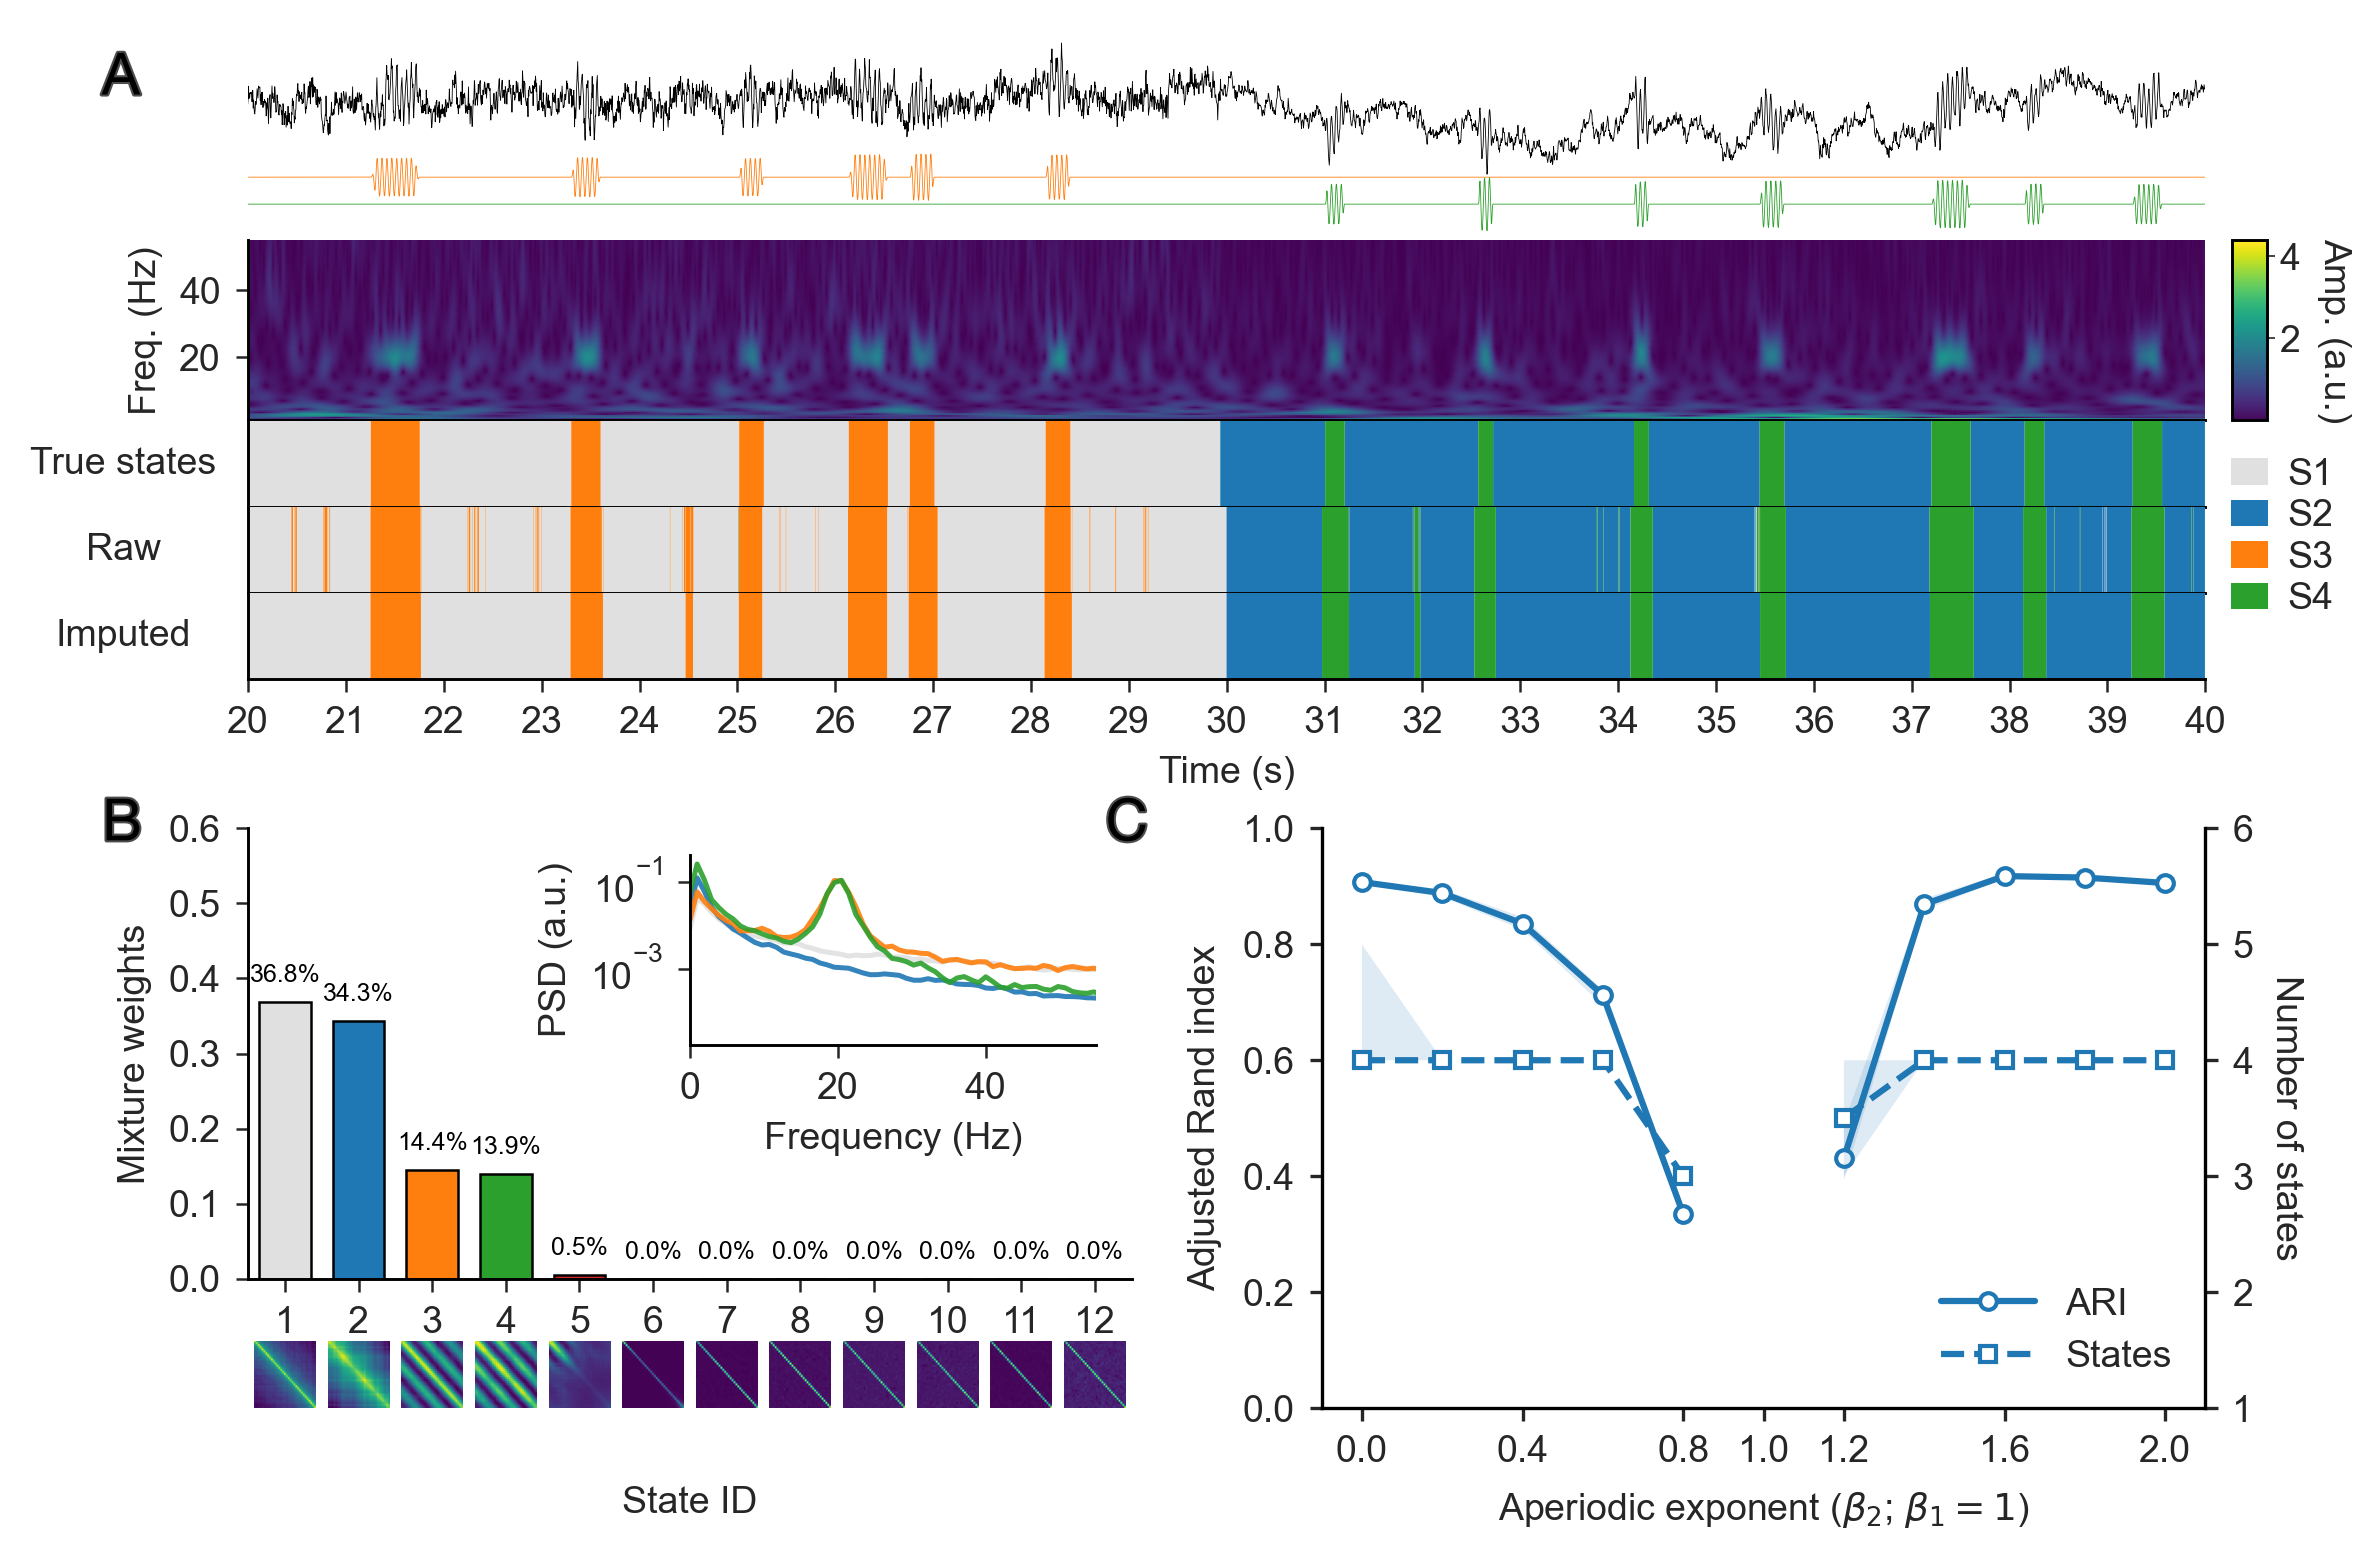

$\beta_2 = 1.6$


In [84]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

plot_t = 40
n_plot = int(round(plot_t * fs))


# One-hot true states
trimmed_states_onehot = np.eye(n_total_states)[trimmed_states.astype(int)]

# Wavelet
t, f, amp = compute_wavelet(
    trimmed_signal[:n_plot],
    fs,
    f_min=1,
    f_max=80,
    df=0.5,
    wavelet="cmor1.5-1.0",
)

# median and across samples


metric = "ari"  # Choose "mcc", "ari", or "kappa".
metric = metric.strip().lower()
if metric not in {"mcc", "ari", "kappa"}:
    raise ValueError("metric must be 'mcc', 'ari', or 'kappa'.")

metric_ylim = (0, 1)  # Use (-1, 1) to include negative scores.


condition_label = "variability_levels"

df_show = df.query(
    'method == "DP-GMM (Imputed & Edge-removed)"'
).copy()

df_plot = (
    df_show.groupby(condition_label)
    .agg(**{
        f"{metric}_median": (metric, "median"),
        f"{metric}_q25": (metric, lambda x: x.quantile(0.25)),
        f"{metric}_q75": (metric, lambda x: x.quantile(0.75)),
        "states_median": ("num_active_states", "median"),
        "states_q25": (
            "num_active_states",
            lambda x: x.quantile(0.25, interpolation="nearest"),
        ),
        "states_q75": (
            "num_active_states",
            lambda x: x.quantile(0.75, interpolation="nearest"),
        ),
    })
    .reset_index()
    .sort_values(condition_label)
)


# beta_2 = 1 (beta_1 = 1) is an unbenchmarked, collapsed two-state case.
# Its plotting coordinate is delta = beta_2 - beta_1 = 0.
# Insert missing summaries so neither lines nor IQR bands bridge this case.
unbenchmarked_x = 0.0
df_plot = df_plot.loc[
    ~np.isclose(
        df_plot[condition_label].to_numpy(dtype=float),
        unbenchmarked_x,
        rtol=0.0,
        atol=1e-12,
    )
].copy()
plot_grid = np.sort(np.append(
    df_plot[condition_label].to_numpy(dtype=float),
    unbenchmarked_x,
))
df_plot = (
    df_plot.set_index(condition_label)
    .reindex(plot_grid)  # New row: NaN for every metric/state summary.
    .rename_axis(condition_label)
    .reset_index()
)

x_ratio = df_plot[condition_label].to_numpy()

mosaic = [
    ["a1", "a1", "."],
    ["a2", "a2", "cbar1"],
    ["a3", "a3", "leg"],
    ["a4", "a4", "leg"],
    ["a5", "a5", "leg"],
    ["gap", "gap", "."],
    ["b", "c", "."],
    ["d", "c", "."],
]

fig, axes = plt.subplot_mosaic(
    mosaic,
    figsize=(FIG_WIDTH + 0.5, 5),
    constrained_layout=True,
    gridspec_kw={
        "height_ratios": [0.7, 0.6, 0.15, 0.15, 0.15, 0.08, 1.5, 0.225],
        "width_ratios": [1, 1, 0.04],
    },
)

fig.set_constrained_layout_pads(
    w_pad=0.0,
    h_pad=0.0,
    wspace=0.01,
    hspace=0.001,
)

axes["gap"].axis("off")

#############
# simulated signal example
############

time_plot = trimmed_time_vec[:n_plot]

axes["a1"].plot(
    time_plot,
    -0.6 + 1.9 * trimmed_signal[:n_plot],
    lw=0.2,
    color="k",
)

axes["a1"].grid(False)
axes["a1"].set_frame_on(False)

scale_burst = 1.9

for state_id in range(2, min(n_true_states, 4)):
    axes["a1"].plot(
        time_plot,
        -2.5 - (2.5 * state_id)
        + scale_burst * (
                trimmed_bursts[:n_plot]
                * (trimmed_states[:n_plot] == state_id)
        ),
        lw=0.2,
        color=colors[state_id],
    )

axes["a1"].tick_params(
    axis="both",
    which="both",
    bottom=False,
    top=False,
    left=False,
    right=False,
    labelbottom=False,
    labelleft=False,
)

#########
# wavelet
#########

im = axes["a2"].imshow(
    amp,
    extent=[t[0], t[-1], f[0], f[-1]],
    origin="lower",
    aspect="auto",
    cmap="viridis",
    vmin=np.nanmin(amp),
    vmax=np.nanmax(amp),
)

axes["a2"].tick_params(
    axis="x",
    which="both",
    bottom=False,
    top=False,
    labelbottom=False,
    labeltop=False,
)
axes["a2"].yaxis.set_major_locator(MultipleLocator(20))
axes["a2"].set_ylim(1, 55)
axes["a2"].set_ylabel("Freq. (Hz)")

cb = fig.colorbar(im, cax=axes["cbar1"])
cb.set_label("Amp. (a.u.)", rotation=270, labelpad=12)
cb.ax.tick_params(which="both", length=2, width=0.4, pad=1)

# Robust SVG/PDF colorbar rendering
if hasattr(cb, "solids") and cb.solids is not None:
    cb.solids.set_edgecolor("face")
    cb.solids.set_rasterized(True)

##########
# true and estimated states
#########
axes["a3"].stackplot(
    time_plot,
    trimmed_states_onehot[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:n_total_states],
)
axes["a3"].set_ylabel("True states", rotation=0, labelpad=30, va="center")

axes["a4"].stackplot(
    time_plot,
    est_states_onehot_raw[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:est_states_onehot_raw.shape[1]],
    labels=[f"S{i + 1}" for i in range(est_states_onehot_raw.shape[1])],
)
axes["a4"].set_ylabel("Raw", rotation=0, labelpad=30, va="center")

axes["a5"].stackplot(
    time_plot,
    est_states_onehot_no_edge_imputed[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:est_states_onehot_no_edge_imputed.shape[1]],
)
axes["a5"].set_ylabel(
    "Imputed",
    rotation=0,
    labelpad=30,
    va="center",
)

for key in ["a1", "a2", "a3", "a4", "a5", ]:
    axes[key].sharex(axes["a1"])

for key in ["a3", "a4", ]:
    axes[key].tick_params(
        axis="x",
        which="both",
        bottom=True,
        labelbottom=False,
        length=0,
    )
    axes[key].tick_params(
        axis="y",
        which="both",
        left=False,
        labelleft=False,
    )
    axes[key].set_yticks([])
    axes[key].set_xticks([])
    axes[key].set_ylim(0, 1)
    axes[key].set_xlim(0, plot_t)
    axes[key].spines["bottom"].set_visible(True)

axes["a5"].set_xlabel("Time (s)")
axes["a5"].xaxis.set_major_locator(MultipleLocator(1.0))
axes["a5"].tick_params(axis="y", which="both", left=False, labelleft=False)
axes["a5"].set_yticks([])
axes["a5"].set_ylim(0, 1)
axes["a5"].set_xlim(20, plot_t)
axes["a5"].spines["bottom"].set_visible(True)

##########
# Legend
#########
handles, labels = axes["a4"].get_legend_handles_labels()

axes["leg"].axis("off")
state_legend = axes["leg"].legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(-2.7, 0.55),
    bbox_transform=axes["leg"].transAxes,
    frameon=False,
    handlelength=1,
    handletextpad=0.5,
    labelspacing=0.2,
    borderaxespad=0.0,
    ncol=1,
    columnspacing=0.4,
)

state_legend.set_in_layout(False)

##########
# mixture weights
# #########

x_states = np.arange(n_raw_states)

axes["b"].bar(
    x_states,
    untrunc_weights_raw,
    width=0.7,
    color=colors[:n_raw_states],
    edgecolor="k",
    linewidth=0.6,
    zorder=2,
)

for k, w in enumerate(untrunc_weights_raw):
    axes["b"].text(
        k,
        w + 0.02,
        f"{w * 100.0:.1f}%",
        ha="center",
        va="bottom",
        color="k",
        fontsize=MY_FONT_SIZE - 3,
    )

axes["b"].set_ylabel("Mixture weights")
axes["b"].set_xticks(x_states, labels=np.arange(1, n_raw_states + 1))
axes["b"].set_ylim(0, 0.6)
axes["b"].set_xlim(-0.5, n_raw_states - 0.5)
axes["b"].tick_params(axis="y")


#inset: dpgmm state psd
b_inset = axes["b"].inset_axes([0.50, 0.52, 0.46, 0.42])

for i in range(num_states_no_edge_imputed):
    b_inset.plot(f_vec[i], psds[i], color=colors[i], lw=1.2, alpha = 0.9)

b_inset.set_xlim(0, 55)
b_inset.set_yscale("log")
b_inset.set_xlabel("Frequency (Hz)")
b_inset.set_ylabel("PSD (a.u.)")


##########
# Selected metric and states across conditions
#########


ax_c, ax_c2 = plot_metrics_states(
    ax=axes["c"],
    df_plot=df_plot,
    x=condition_label,
    metric=metric,
    mcc_ylim=metric_ylim,
    xlabel="Exponents",
    linewidth=1.5,
)

# Include the missing condition explicitly: delta = 0 is labeled beta_2 = 1.
ticks = np.sort(np.unique(np.append(
    np.arange(-1.0, 1.01, 0.4),
    unbenchmarked_x,
)))
ax_c.set_xticks(ticks)

ax_c.set_xticklabels([f"{1 + v:.1f}" for v in ticks])
ax_c.set_xlabel(
    r"Aperiodic exponent ($\beta_2$; $\beta_1=1$)"
)


handles_metric, labels_metric = ax_c.get_legend_handles_labels()
handles_states, labels_states = ax_c2.get_legend_handles_labels()

ax_c2.legend(
    handles_metric + handles_states,
    labels_metric + labels_states,
    loc="lower right",
    frameon=False,
    fontsize=9,
    ncol=1,
    handlelength=2.5,
    columnspacing=0.8,
    labelcolor="0.15",
)



# ------------------------------------------------------------
# D: covariance thumbnails
# ------------------------------------------------------------

thumb_half_width = 0.42
thumb_y0 = -0.02
thumb_y1 = 0.8

axes["d"].set_xlim(-0.5, n_raw_states - 0.5)

for k in range(n_raw_states):
    im_dpgmm_cov = axes["d"].imshow(
        untrunc_covs_raw[k],
        extent=(
            k - thumb_half_width,
            k + thumb_half_width,
            thumb_y0,
            thumb_y1,
        ),
        cmap="viridis",
        origin="upper",
        aspect="auto",
    )
    im_dpgmm_cov.set_rasterized(True)

axes["d"].set_xlabel("State ID")
axes["d"].set_xlim(-0.5, n_raw_states - 0.5)
axes["d"].set_ylim(thumb_y0, thumb_y1)
axes["d"].set_xticks([])
axes["d"].set_yticks([])

for spine in axes["d"].spines.values():
    spine.set_visible(False)

fig.align_xlabels([axes["c"], axes["d"]])

fig.canvas.draw()
fig.set_constrained_layout(False)

state_keys = ["a3", "a4", "a5"]

pos = [axes[k].get_position() for k in state_keys]

x0 = min(p.x0 for p in pos)
x1 = max(p.x1 for p in pos)
y_top = max(p.y1 for p in pos)
y_bottom = min(p.y0 for p in pos)

n_rows = len(state_keys)
gap = 0.0
total_h = y_top - y_bottom
row_h = (total_h - gap * (n_rows - 1)) / n_rows

y1 = y_top

for key in state_keys:
    y0 = y1 - row_h
    axes[key].set_position([x0, y0, x1 - x0, row_h])
    y1 = y0 - gap

wavelet_cbar_left_shift = 0.014

pos_cbar1 = axes["cbar1"].get_position()
axes["cbar1"].set_position([
    pos_cbar1.x0 - wavelet_cbar_left_shift,
    pos_cbar1.y0,
    pos_cbar1.width,
    pos_cbar1.height,
])

###########
# panel label
###########

import matplotlib.patheffects as pe
from matplotlib.font_manager import FontProperties

# Finalize constrained_layout positions before reading axes positions
fig.canvas.draw()
fig.set_constrained_layout(False)

panel_font = FontProperties(
    family="Helvetica Neue",
    weight="heavy",
    size=14,
)

label_kw = dict(
    fontproperties=panel_font,
    color="k",
    ha="left",
    va="top",
    path_effects=[
        pe.withStroke(linewidth=1, foreground="0.30")
    ],
)

# Get axes positions in figure coordinates
pos_a = axes["a1"].get_position()
pos_b = axes["b"].get_position()
pos_c = axes["c"].get_position()

# A and B aligned to the same absolute figure x-position
x_left = 0.03

fig.text(
    x_left,
    min(pos_a.y1 + 0.035, 0.985),
    "A",
    transform=fig.transFigure,
    **label_kw,
)

fig.text(
    x_left,
    pos_b.y1 + 0.020,
    "B",
    transform=fig.transFigure,
    **label_kw,
)

fig.text(
    pos_c.x0 - 0.09,
    pos_c.y1 + 0.020,
    "C",
    transform=fig.transFigure,
    **label_kw,
)

#fig.suptitle(fr"$\beta_2 = {exponent[1]}$", fontsize=13, fontweight="bold", y=1.05)

# Shift colorbar slightly to the left
fig.canvas.draw()

pos = axes["cbar1"].get_position()
axes["cbar1"].set_position([
    pos.x0 - 0.019,  # Shift left
    pos.y0,
    pos.width,
    pos.height,
])


save_path = fig_dir / f"{sim_cond}"


for fmt in ["svg", "pdf"]:
    fig.savefig(
        save_path.with_suffix(f".{fmt}"),
        format=fmt,
        bbox_inches="tight",
        pad_inches=0.1,
        dpi=900,
    )


print(f"Figure saved to: {save_path}")

plt.show()

print(fr"$\beta_2 = {exponent[1]}$")


# Varying signal duration

In [41]:
sim_cond = "signal_duration"

signal_dir = "../data/simulations"
performance_dir = "../data/performance"

fig_dir = Path("../figures") / str(sim_cond)
fig_dir.mkdir(parents=True, exist_ok=True)


fs = 100
seed_base = 2026
n_samples = 10

# ============================================================
# Experimental condition: signal duration
# ============================================================

# Experimental condition: signal duration
n_seconds_vec = np.array([
    10,  # 10 sec
    30,  # 30 sec
    60,  # 1 min
    180,  # 3 min
    600,  # 10 min
    1800,  # 30 min
    3600,  # 1 hour
    10800,  # 3 hours
])

n_conditions = len(n_seconds_vec)

max_seconds = int(np.max(n_seconds_vec))
max_n_times = int(fs * max_seconds)
print("Maximum signal duration:", max_seconds, "seconds")
print("Maximum number of samples:", max_n_times)

from functools import lru_cache


@lru_cache(maxsize=1)
def _load_sample(sample_id):
    data_file = os.path.join(
        signal_dir,
        f"{sim_cond}_sample_{sample_id}.npz",
    )

    with np.load(data_file, allow_pickle=False) as sim_data:
        signal_sample = sim_data["signal_sample"]
        states_sample = sim_data["states_sample"]
        bursts_sample = sim_data["bursts_sample"]

    return signal_sample, states_sample, bursts_sample


signal_sample = []
states_sample = []
bursts_sample = []
for i in range(n_samples):
    signal, states, bursts = _load_sample(i)
    signal_sample.append(signal)
    states_sample.append(states)
    bursts_sample.append(bursts)

performance_dir = "../data/performance"
file_path = f"{performance_dir}/results_{sim_cond}.pkl"

import pickle
with open(file_path, "rb") as f:
    res = pickle.load(f)

df_list = []

for sample_id, r in enumerate(res):
    df_sample = pd.DataFrame(r)

    # Preserve existing IDs; assign only if absent.
    if "sample_id" not in df_sample.columns:
        df_sample["sample_id"] = sample_id

    df_list.append(df_sample)

df = pd.concat(df_list, ignore_index=True)

df["burst_f"] = df["burst_f"].apply(tuple)

df["num_active_states"] = df["est_params"].apply(
    lambda x: x.get("num_active_states", np.nan)
    if isinstance(x, dict) else np.nan
)

df.head(30)

Maximum signal duration: 10800 seconds
Maximum number of samples: 1080000


,sample_id,signal,true_states,burst_f,fs,snr,n_seconds,est_params,loss_best,model_id_best,...,matched_est_states,state_labels,order,summary_stats,mcc,ari,kappa,loss,method,num_active_states
0,0,"[1.1056105717087052, 1.1194164033115557, -0.09...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,10,"{'alpha': 0.32251382, 'weights': [0.8383712, 0...",1.067306,8,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1]","[0, 1]",None,0.768504,0.796556,0.765306,1.067306,DP-GMM,2
1,0,"[1.1056105717087052, 1.1194164033115557, -0.09...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,10,"{'alpha': 0.32251382, 'weights': [0.8383712, 0...",1.067306,8,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1]","[0, 1]",None,0.768504,0.796556,0.765306,1.067306,DP-GMM (Edge-removed),2
2,0,"[1.1056105717087052, 1.1194164033115557, -0.09...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,10,"{'alpha': 0.32251382, 'weights': [0.8383712, 0...",1.067306,8,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1]","[0, 1]",None,0.813299,0.826380,0.808658,1.067306,DP-GMM (Imputed),2
3,0,"[1.1056105717087052, 1.1194164033115557, -0.09...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,10,"{'alpha': 0.32251382, 'weights': [0.8383712, 0...",1.067306,8,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1]","[0, 1]",None,0.813299,0.826380,0.808658,1.067306,DP-GMM (Imputed & Edge-removed),2
4,0,"[1.245438979453294, 1.2604070587930811, -0.055...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,30,"{'alpha': 0.6183875, 'weights': [0.8140016, 0....",1.129594,0,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2]","[0, 1, 2]",None,0.846313,0.818617,0.842956,1.129594,DP-GMM,3
5,0,"[1.245438979453294, 1.2604070587930811, -0.055...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,30,"{'alpha': 0.6183875, 'weights': [0.8140016, 0....",1.129594,0,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2]","[0, 1, 2]",None,0.846313,0.818617,0.842956,1.129594,DP-GMM (Edge-removed),3
6,0,"[1.245438979453294, 1.2604070587930811, -0.055...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,30,"{'alpha': 0.6183875, 'weights': [0.8140016, 0....",1.129594,0,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2]","[0, 1, 2]",None,0.866401,0.827467,0.861369,1.129594,DP-GMM (Imputed),3
7,0,"[1.245438979453294, 1.2604070587930811, -0.055...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,30,"{'alpha': 0.6183875, 'weights': [0.8140016, 0....",1.129594,0,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2]","[0, 1, 2]",None,0.866401,0.827467,0.861369,1.129594,DP-GMM (Imputed & Edge-removed),3
8,0,"[0.5519163608147342, 0.5643553575668199, -0.52...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,60,"{'alpha': 0.5134122, 'weights': [0.7965527, 0....",0.976510,5,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2]","[0, 1, 2]",None,0.818958,0.783457,0.816160,0.976510,DP-GMM,3
9,0,"[0.5519163608147342, 0.5643553575668199, -0.52...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,60,"{'alpha': 0.5134122, 'weights': [0.7965527, 0....",0.976510,5,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2]","[0, 1, 2]",None,0.818958,0.783457,0.816160,0.976510,DP-GMM (Edge-removed),3


In [42]:
sample_id = 0
n_seconds = 30
cond_id = np.where(np.isclose(n_seconds_vec, n_seconds))[0][0]
fs = 250

,sample_id,signal,true_states,burst_f,fs,snr,n_seconds,est_params,loss_best,model_id_best,...,matched_est_states,state_labels,order,summary_stats,mcc,ari,kappa,loss,method,num_active_states
0,0,"[1.1056105717087052, 1.1194164033115557, -0.09...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,10,"{'alpha': 0.32251382, 'weights': [0.8383712, 0...",1.067306,8,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1]","[0, 1]",None,0.768504,0.796556,0.765306,1.067306,DP-GMM,2
1,0,"[1.1056105717087052, 1.1194164033115557, -0.09...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,10,"{'alpha': 0.32251382, 'weights': [0.8383712, 0...",1.067306,8,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1]","[0, 1]",None,0.768504,0.796556,0.765306,1.067306,DP-GMM (Edge-removed),2
2,0,"[1.1056105717087052, 1.1194164033115557, -0.09...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,10,"{'alpha': 0.32251382, 'weights': [0.8383712, 0...",1.067306,8,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1]","[0, 1]",None,0.813299,0.826380,0.808658,1.067306,DP-GMM (Imputed),2
3,0,"[1.1056105717087052, 1.1194164033115557, -0.09...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,10,"{'alpha': 0.32251382, 'weights': [0.8383712, 0...",1.067306,8,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1]","[0, 1]",None,0.813299,0.826380,0.808658,1.067306,DP-GMM (Imputed & Edge-removed),2
4,0,"[1.245438979453294, 1.2604070587930811, -0.055...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20, 40)",100,0,30,"{'alpha': 0.6183875, 'weights': [0.8140016, 0....",1.129594,0,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2]","[0, 1, 2]",None,0.846313,0.818617,0.842956,1.129594,DP-GMM,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
555,19,"[-0.5331088770379058, 0.02336606216056143, -1....","[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, ...","(20, 40)",100,0,1800,"{'alpha': 0.8577168, 'weights': [0.43586105, 0...",0.857355,3,...,"[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, ...","[0, 1, 2, 3, 4, 5]","[0, 2, 4, 1, 3, 5]",None,0.806424,0.714577,0.806325,0.857355,DP-GMM (Imputed & Edge-removed),6
556,19,"[-0.601827103846678, -0.05724285373127256, -1....","[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, ...","(20, 40)",100,0,3600,"{'alpha': 0.8232753, 'weights': [0.3288301, 0....",0.840019,6,...,"[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, ...","[0, 1, 2, 3, 4, 5, 6, 7, 8]","[0, 2, 4, 1, 3, 5, 6, 7, 8]",None,0.548138,0.436211,0.512077,0.840019,DP-GMM,9
557,19,"[-0.601827103846678, -0.05724285373127256, -1....","[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, ...","(20, 40)",100,0,3600,"{'alpha': 0.8232753, 'weights': [0.34808528, 0...",0.840019,6,...,"[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, ...","[0, 1, 2, 3, 4]","[0, 2, 4, 1, 3]",None,0.577032,0.435083,0.540487,0.840019,DP-GMM (Edge-removed),5
558,19,"[-0.601827103846678, -0.05724285373127256, -1....","[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, ...","(20, 40)",100,0,3600,"{'alpha': 0.8232753, 'weights': [0.3288301, 0....",0.840019,6,...,"[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, ...","[0, 1, 2, 3, 4, 5, 6, 7, 8]","[0, 2, 4, 1, 3, 5, 6, 7, 8]",None,0.742251,0.646623,0.740076,0.840019,DP-GMM (Imputed),9


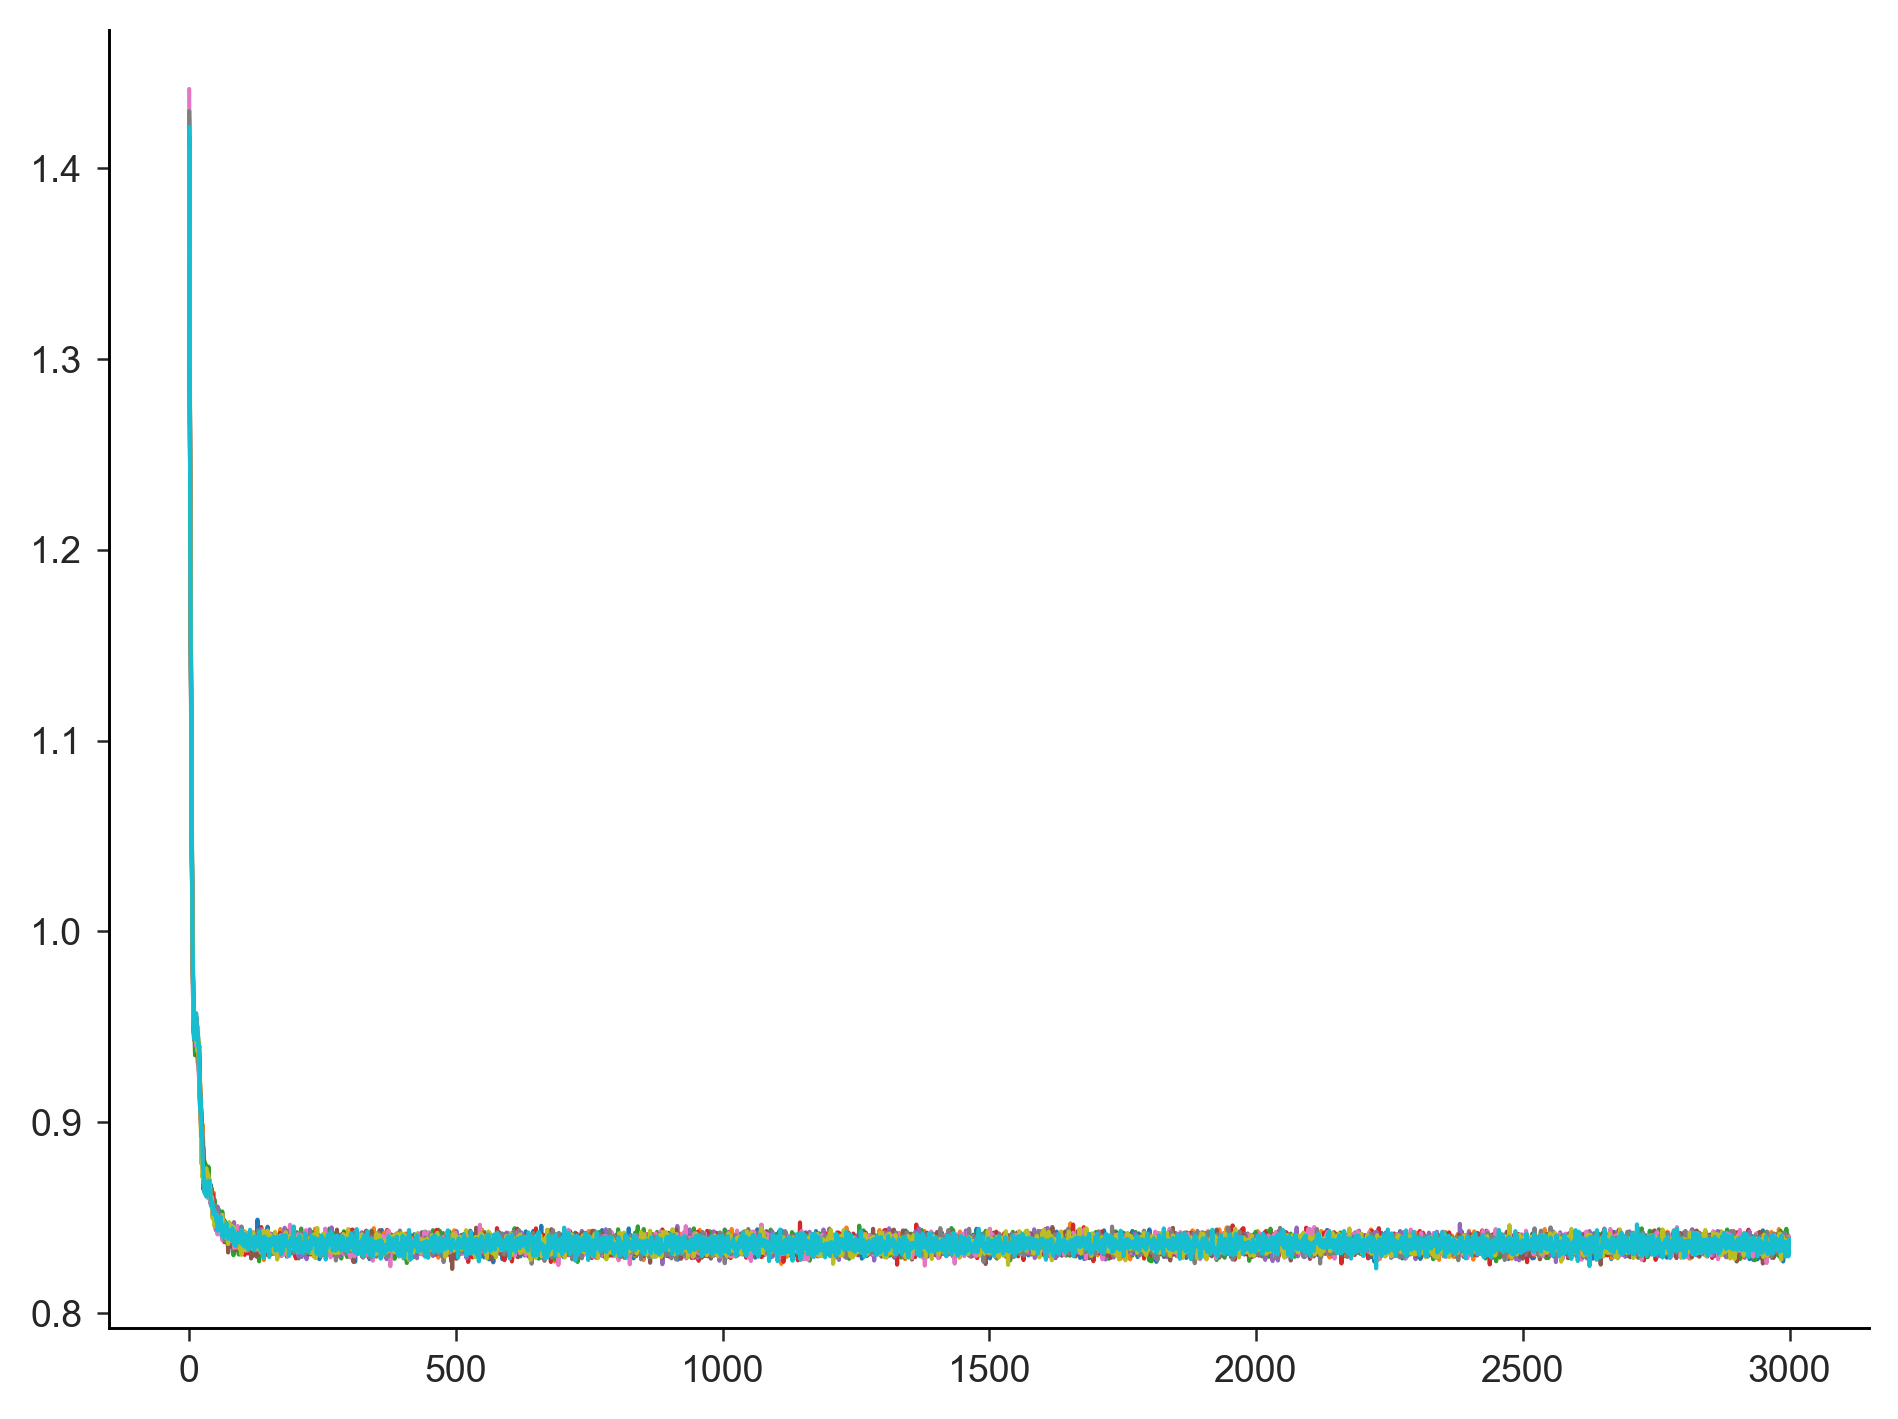

In [46]:
sample_id = 0
n_seconds = df["n_seconds"].unique()[-1]
cond_id = np.where(np.isclose(n_seconds_vec, n_seconds))[0][0]
fs = 250


# Select the correct sample and condition for each method
def select_result(method):
    selected = df.query(
        "method == @method & "
        "sample_id == @sample_id & "
        "n_seconds == @n_seconds"
    )

    if len(selected) != 1:
        raise ValueError(
            f"Expected 1 result for {method}, got {len(selected)}"
        )

    return selected.iloc[0]

df_raw = select_result("DP-GMM")
losses = np.array(df_raw["loss_all"])

plt.plot(np.arange(len(losses[0])), losses.T)


In [48]:
from nds_toolbox.preprocessing.features import trim_data
import numpy as np

# ============================================================
# Select simulation
# ============================================================
sample_id = 0
n_seconds = df["n_seconds"].unique()[-1]
cond_id = np.where(np.isclose(n_seconds_vec, n_seconds))[0][0]
fs = 100


# Select the correct sample and condition for each method
def select_result(method):
    selected = df.query(
        "method == @method & "
        "sample_id == @sample_id & "
        "n_seconds == @n_seconds"
    )

    if len(selected) != 1:
        raise ValueError(
            f"Expected 1 result for {method}, got {len(selected)}"
        )

    return selected.iloc[0]

df_raw = select_result("DP-GMM")
df_no_edge = select_result("DP-GMM (Edge-removed)")
df_no_edge_imputed = select_result(
    "DP-GMM (Imputed & Edge-removed)"
)

# ============================================================
# Common data across variants
# ============================================================


n_times = int(round(n_seconds * fs))

signal = signal_sample[sample_id][:n_times]
bursts = bursts_sample[sample_id][:n_times]
true_states = states_sample[sample_id][:n_times].astype(int)

num_emb = int(df_raw["num_emb"])

trimmed_signal = trim_data(signal, num_emb, verbose=False)
trimmed_bursts = trim_data(bursts, num_emb, verbose=False)
trimmed_states = trim_data(true_states, num_emb, verbose=False)

num_states_true = int(trimmed_states.max() + 1)
true_states_onehot = np.eye(num_states_true)[trimmed_states]

trimmed_time_vec = np.arange(len(trimmed_states)) / fs


# Handle missing state labels (-1) correctly
def states_to_onehot(states, n_states):
    states = np.asarray(states, dtype=int)
    onehot = np.zeros((len(states), n_states), dtype=float)

    valid = states >= 0

    if np.any(states[valid] >= n_states):
        raise ValueError("State labels exceed n_states")

    onehot[np.flatnonzero(valid), states[valid]] = 1

    return onehot


# ============================================================
# Raw DP-GMM
# ============================================================
mcc_raw = df_raw["mcc"]
ari_raw = df_raw["ari"]
kappa_raw = df_raw["kappa"]


num_states = int(df_raw["num_states"])

est_params_raw = df_raw["est_params"]

weights_raw = est_params_raw["weights"]
means_raw = est_params_raw["means"]
covs_raw = est_params_raw["covs"]
alpha_raw = est_params_raw["alpha"]

num_states_raw = len(weights_raw)

est_states_raw = np.asarray(df_raw["est_states"], dtype=int)
est_states_onehot_raw = states_to_onehot(
    est_states_raw, num_states_raw
)

untrunc_weights_raw = est_params_raw["untrunc_weights"]
untrunc_means_raw = est_params_raw["untrunc_means"]
untrunc_covs_raw = est_params_raw["untrunc_covs"]
order = df_raw["order"]
# -----------------------------
# Extract diagonals and compute CV
# -----------------------------
diags = [np.diag(cov) for cov in untrunc_covs_raw]

cv_vals = []
for d in diags:
    mu = np.mean(d)
    sd = np.std(d)
    cv = sd / (mu + 1e-12)
    cv_vals.append(cv)

cv_vals = np.array(cv_vals)

# ============================================================
# DP-GMM with edge removal
# ============================================================
num_states_no_edge = int(df_no_edge["num_states"])
est_states_no_edge = np.asarray(
    df_no_edge["est_states"], dtype=int
)

est_states_onehot_no_edge = states_to_onehot(
    est_states_no_edge, num_states_no_edge
)


mcc_no_edge = df_no_edge["mcc"]
ari_no_edge = df_no_edge["ari"]
kappa_no_edge = df_no_edge["kappa"]

# ============================================================
# DP-GMM with edge removal and imputation
# ============================================================
num_states_no_edge_imputed = int(
    df_no_edge_imputed["num_states"]
)

est_states_no_edge_imputed = np.asarray(
    df_no_edge_imputed["est_states"], dtype=int
)

est_states_onehot_no_edge_imputed = states_to_onehot(
    est_states_no_edge_imputed,
    num_states_no_edge_imputed,
)

mcc_no_edge_imputed = df_no_edge_imputed["mcc"]
ari_no_edge_imputed = df_no_edge_imputed["ari"]
kappa_no_edge_imputed = df_no_edge_imputed["kappa"]


# ============================================================
# Summary
# ============================================================
print("Sample ID:", sample_id)
print("Condition ID:", cond_id)
print("Rise ratio:", n_seconds)

print("Upper bound:", num_states)
print("Active states:", num_states_raw)
print("Active states (no edges):", num_states_no_edge)
print("True states:", num_states_true)

print("MCC (raw):", mcc_raw)
print("MCC (without edge):", mcc_no_edge)
print("MCC (without edge & imputed):", mcc_no_edge_imputed)

print()
print("ARI (raw):", ari_raw)
print("ARI (without edge):", ari_no_edge)
print("ARI (without edge & imputed):", ari_no_edge_imputed)

print()
print("Kappa (raw):", kappa_raw)
print("Kappa (without edge):", kappa_no_edge)
print("Kappa (with edge):", kappa_no_edge_imputed)

Sample ID: 0
Condition ID: 6
Rise ratio: 3600
Upper bound: 13
Active states: 10
Active states (no edges): 13
True states: 3
MCC (raw): 0.5324212960720867
MCC (without edge): 0.5404719778772934
MCC (without edge & imputed): 0.7295471909819131

ARI (raw): 0.5349172174341863
ARI (without edge): 0.5345682251711615
ARI (without edge & imputed): 0.7084245779018119

Kappa (raw): 0.5124445491497938
Kappa (without edge): 0.520806457761127
Kappa (with edge): 0.7198096793215341


Figure saved to: /Users/yamadashoto/Library/Mobile Documents/com~apple~CloudDocs/PhD German/project/TDE-DP-GMM/figures/signal_duration/signal_duration_3600_ari.svg
Figure saved to: /Users/yamadashoto/Library/Mobile Documents/com~apple~CloudDocs/PhD German/project/TDE-DP-GMM/figures/signal_duration/signal_duration_3600_ari.pdf


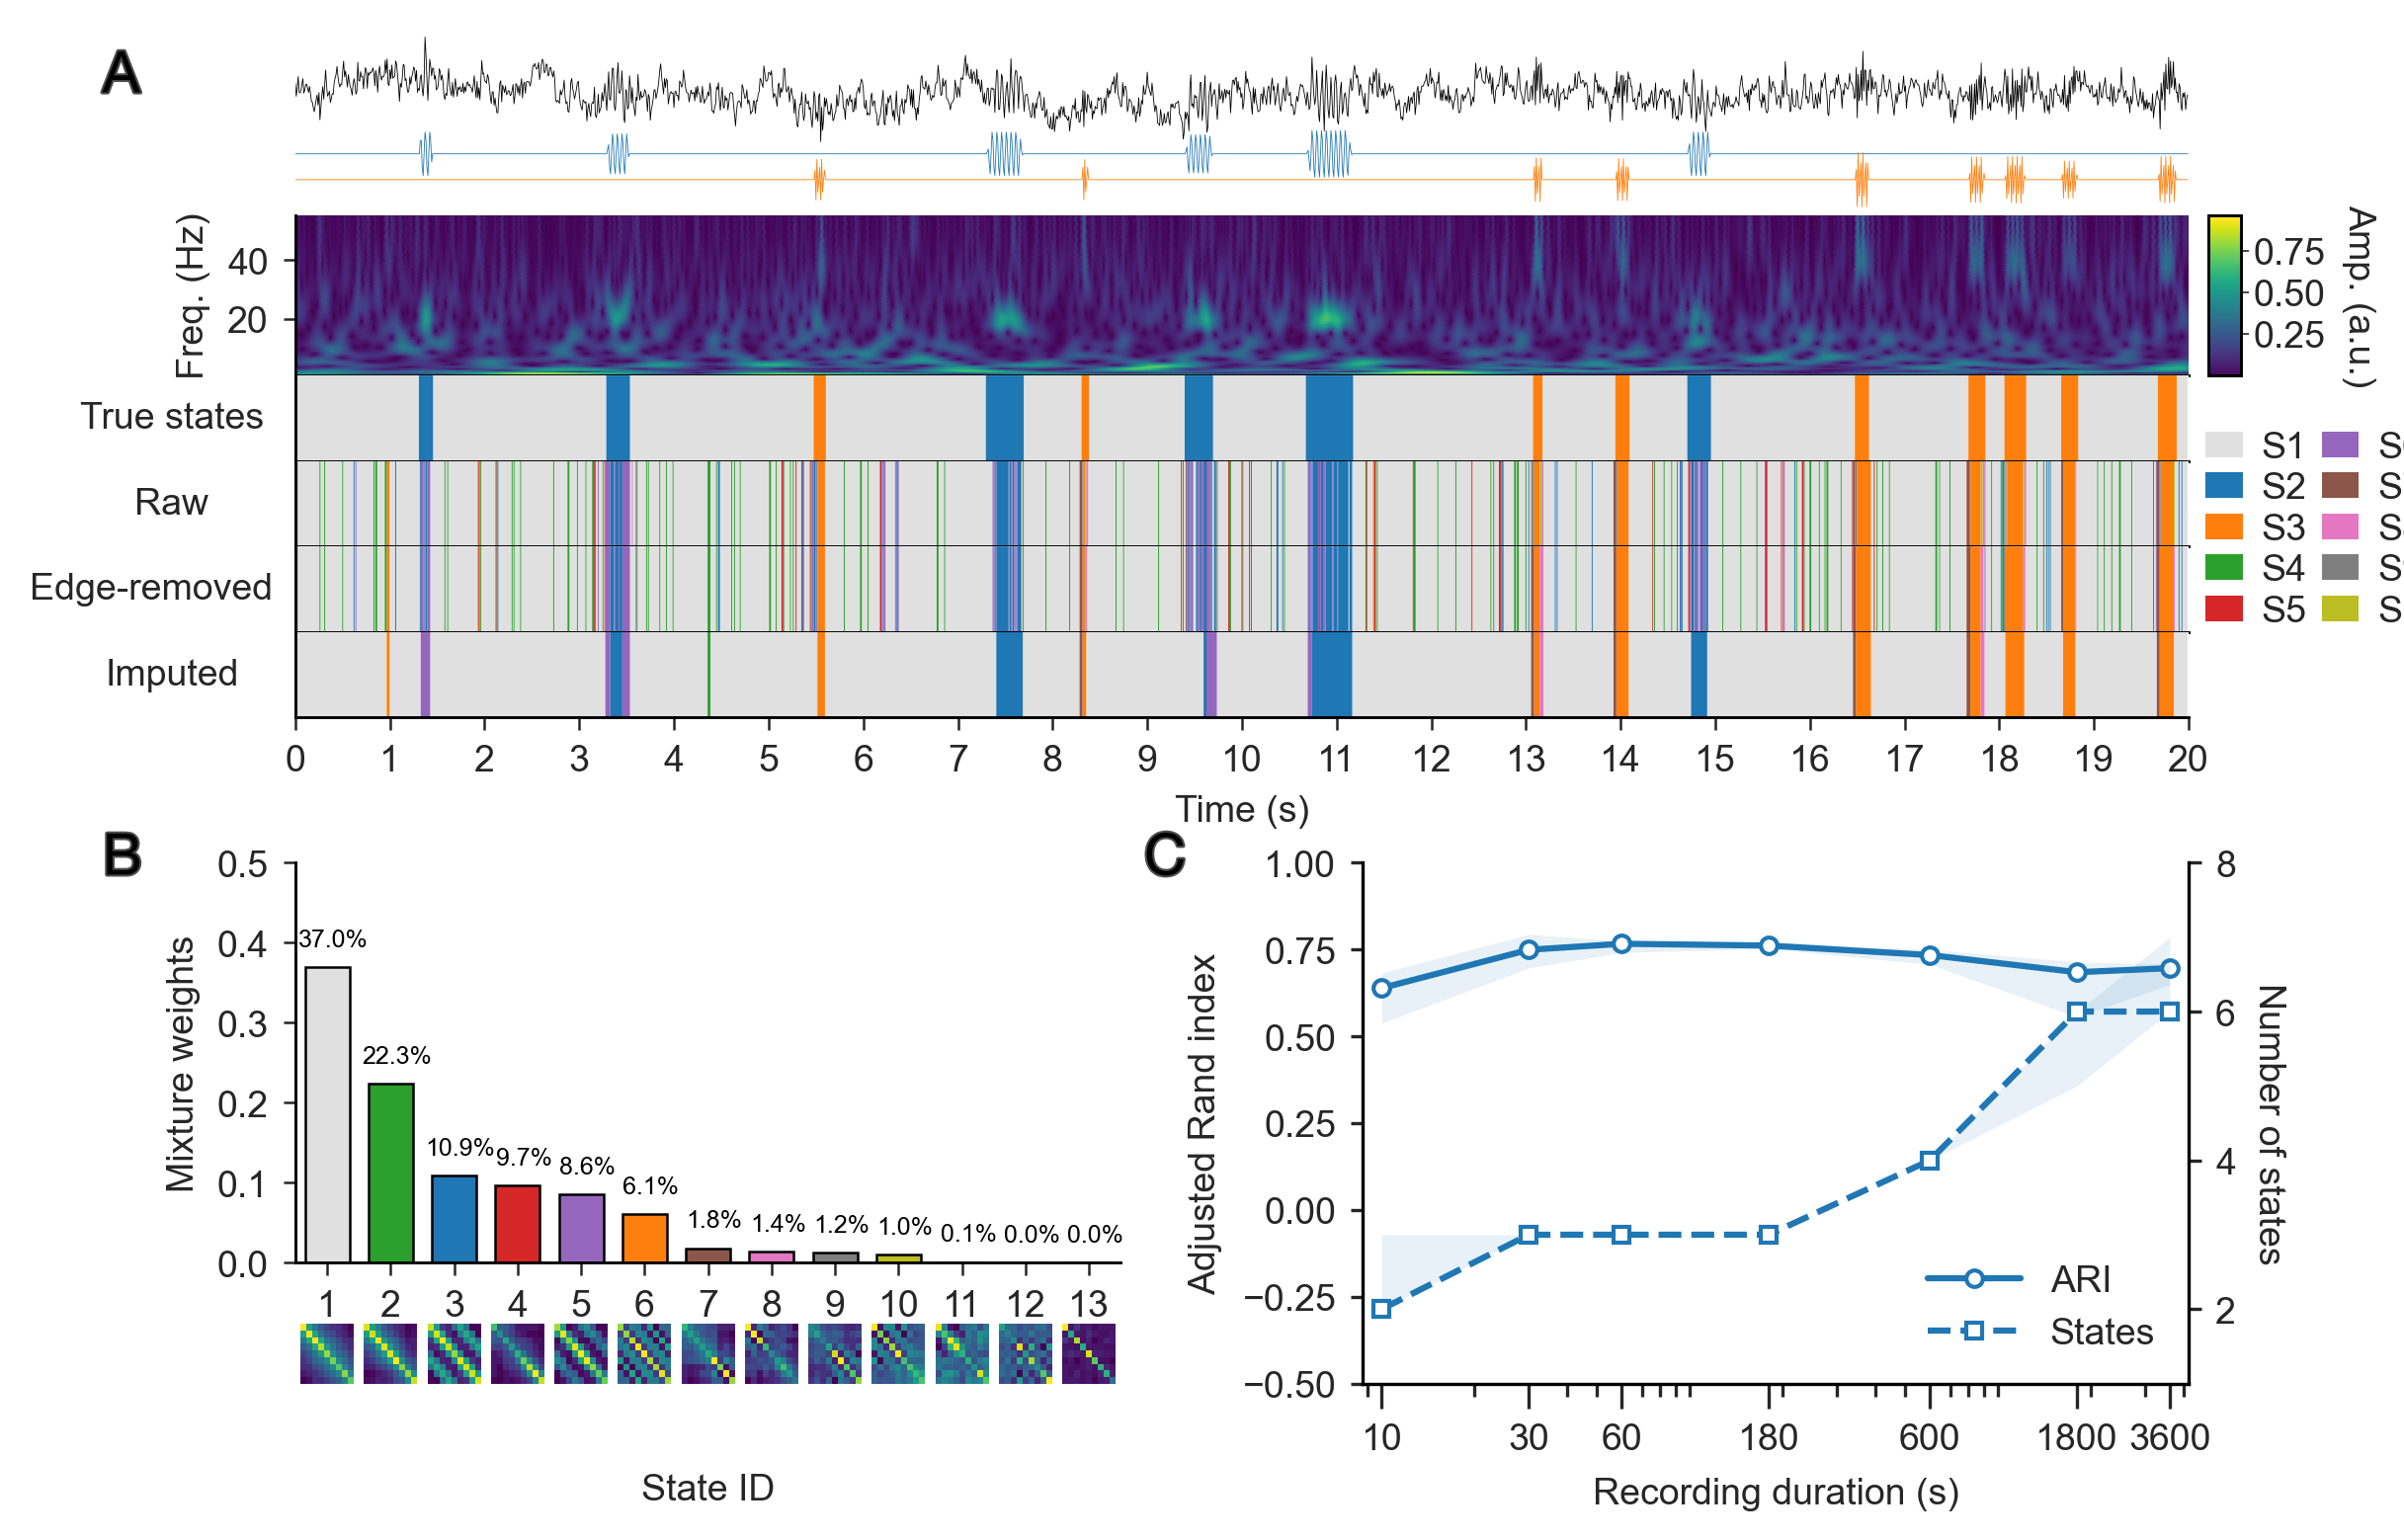

In [51]:

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# Select the existing score column in df: "ari", "mcc", or "kappa".
metric = "ari"
metric = metric.strip().lower()
metric_limits = {
    "ari": (-0.5, 1.0),
    "mcc": (-1.0, 1.0),
    "kappa": (-1.0, 1.0),
}
if metric not in metric_limits:
    raise ValueError("metric must be 'ari', 'mcc', or 'kappa'.")
metric_ylim = metric_limits[metric]

plot_t = 20
n_plot = int(round(plot_t * fs))

n_true_states = int(np.nanmax(trimmed_states)) + 1
n_raw_states = len(untrunc_weights_raw)

n_total_states = max(n_true_states, n_raw_states, num_states_raw)

cmap = plt.get_cmap("tab10")

colors = ["#E0E0E0"] + [cmap(i % 10) for i in range(n_total_states - 1)]
state_labels = [f"S{i}" for i in range(n_total_states)]

# One-hot true states
trimmed_states_onehot = np.eye(n_total_states)[trimmed_states.astype(int)]

# Wavelet
t, f, amp = compute_wavelet(
    trimmed_signal[:n_plot],
    fs,
    f_min=1,
    f_max=80,
    df=0.5,
    wavelet="cmor1.5-1.0",
)

# Median and interquartile range across samples.
cond1_label = "n_seconds"
method_label = "DP-GMM (Imputed & Edge-removed)"
required_columns = {"method", cond1_label, metric, "num_active_states"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing columns in df: {sorted(missing_columns)}")

df_show = df.loc[df["method"].eq(method_label)].copy()
if df_show.empty:
    raise ValueError(f"No rows found for method {method_label!r}.")

for column in (cond1_label, metric, "num_active_states"):
    df_show[column] = pd.to_numeric(df_show[column], errors="raise").astype(float)

duration_values = df_show[cond1_label].to_numpy()
if not np.all(np.isfinite(duration_values) & (duration_values > 0)):
    raise ValueError("Recording durations must be finite and positive for a log axis.")

score_values = df_show[metric].to_numpy()
if np.isinf(score_values).any():
    raise ValueError(f"{metric.upper()} contains infinite values.")
valid_scores = np.isfinite(score_values)
if not valid_scores.any():
    raise ValueError(f"No defined {metric.upper()} scores for {method_label!r}.")
if np.any((score_values[valid_scores] < metric_ylim[0]) |
          (score_values[valid_scores] > metric_ylim[1])):
    raise ValueError(f"{metric.upper()} scores fall outside {metric_ylim}.")
if not valid_scores.all():
    warnings.warn(
        f"{np.count_nonzero(~valid_scores)} missing/undefined {metric.upper()} "
        f"scores are excluded from score summaries. Inspect df_plot['{metric}_n'] "
        "for valid counts; durations with no valid score remain gaps. "
        "State-count summaries still use all available state counts.",
        RuntimeWarning,
        stacklevel=2,
    )

state_count_values = df_show["num_active_states"].to_numpy()
if np.isinf(state_count_values).any() or not np.isfinite(state_count_values).any():
    raise ValueError("State counts must contain finite values and no infinities.")

df_plot = (
    df_show.groupby(cond1_label)
    .agg(**{
        f"{metric}_median": (metric, "median"),
        f"{metric}_q25": (metric, lambda x: x.quantile(0.25)),
        f"{metric}_q75": (metric, lambda x: x.quantile(0.75)),
        f"{metric}_n": (metric, "count"),
        "n_rows": (metric, "size"),
        "states_n": ("num_active_states", "count"),
        "states_median": ("num_active_states", "median"),
        "states_q25": (
            "num_active_states",
            lambda x: x.quantile(0.25, interpolation="nearest"),
        ),
        "states_q75": (
            "num_active_states",
            lambda x: x.quantile(0.75, interpolation="nearest"),
        ),
    })
    .reset_index()
    .sort_values(cond1_label)
)


mosaic = [
    ["a1", "a1", "."],
    ["a2", "a2", "cbar1"],
    ["a3", "a3", "leg"],
    ["a4", "a4", "leg"],
    ["a5", "a5", "leg"],
    ["a6", "a6", "leg"],
    ["gap", "gap", "."],
    ["b", "c", "."],
    ["d", "c", "."],
]

fig, axes = plt.subplot_mosaic(
    mosaic,
    figsize=(FIG_WIDTH + 0.7, 5),
    constrained_layout=True,
    gridspec_kw={
        "height_ratios": [0.7, 0.6, 0.15, 0.15, 0.15, 0.15, 0.08, 1.5, 0.225],
        "width_ratios": [1, 1, 0.04],
    },
)

fig.set_constrained_layout_pads(
    w_pad=0.0,
    h_pad=0.0,
    wspace=0.01,
    hspace=0.001,
)

axes["gap"].axis("off")

#############
# simulated signal example
############

time_plot = trimmed_time_vec[:n_plot]

axes["a1"].plot(
    time_plot,
    1.5 * trimmed_signal[:n_plot],
    lw=0.2,
    color="k",
)

axes["a1"].grid(False)
axes["a1"].set_frame_on(False)

scale_burst = 1.8

for state_id in range(1, min(n_true_states, 4)):
    axes["a1"].plot(
        time_plot,
        -2 - state_id
        + scale_burst * (
                trimmed_bursts[:n_plot]
                * (trimmed_states[:n_plot] == state_id)
        ),
        lw=0.2,
        color=colors[state_id],
    )

axes["a1"].tick_params(
    axis="both",
    which="both",
    bottom=False,
    top=False,
    left=False,
    right=False,
    labelbottom=False,
    labelleft=False,
)

#########
# wavelet
#########

im = axes["a2"].imshow(
    amp,
    extent=[t[0], t[-1], f[0], f[-1]],
    origin="lower",
    aspect="auto",
    cmap="viridis",
    vmin=np.nanmin(amp),
    vmax=np.nanmax(amp),
)

axes["a2"].tick_params(
    axis="x",
    which="both",
    bottom=False,
    top=False,
    labelbottom=False,
    labeltop=False,
)
axes["a2"].yaxis.set_major_locator(MultipleLocator(20))
axes["a2"].set_ylim(1, 55)
axes["a2"].set_ylabel("Freq. (Hz)")

cb = fig.colorbar(im, cax=axes["cbar1"])
cb.set_label("Amp. (a.u.)", rotation=270, labelpad=12)
cb.ax.tick_params(which="both", length=2, width=0.4, pad=1)

# Robust SVG/PDF colorbar rendering
if hasattr(cb, "solids") and cb.solids is not None:
    cb.solids.set_edgecolor("face")
    cb.solids.set_rasterized(True)

##########
# true and estimated states
#########
axes["a3"].stackplot(
    time_plot,
    trimmed_states_onehot[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:n_total_states],
)
axes["a3"].set_ylabel("True states", rotation=0, labelpad=30, va="center")

axes["a4"].stackplot(
    time_plot,
    est_states_onehot_raw[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:est_states_onehot_raw.shape[1]],
    labels=[f"S{i + 1}" for i in range(est_states_onehot_raw.shape[1])],
)
axes["a4"].set_ylabel("Raw", rotation=0, labelpad=30, va="center")

axes["a5"].stackplot(
    time_plot,
    est_states_onehot_no_edge[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:est_states_onehot_no_edge.shape[1]],
)
axes["a5"].set_ylabel("Edge-removed", rotation=0, labelpad=35, va="center")

axes["a6"].stackplot(
    time_plot,
    est_states_onehot_no_edge_imputed[:n_plot].T,
    linewidth=0,
    step="mid",
    edgecolor="none",
    colors=colors[:est_states_onehot_no_edge_imputed.shape[1]],
)
axes["a6"].set_ylabel(
    "Imputed",
    rotation=0,
    labelpad=30,
    va="center",
)

for key in ["a1", "a2", "a3", "a4", "a5", "a6"]:
    axes[key].sharex(axes["a1"])

for key in ["a3", "a4", "a5"]:
    axes[key].tick_params(
        axis="x",
        which="both",
        bottom=True,
        labelbottom=False,
        length=0,
    )
    axes[key].tick_params(
        axis="y",
        which="both",
        left=False,
        labelleft=False,
    )
    axes[key].set_yticks([])
    axes[key].set_xticks([])
    axes[key].set_ylim(0, 1)
    axes[key].set_xlim(0, plot_t)
    axes[key].spines["bottom"].set_visible(True)

axes["a6"].set_xlabel("Time (s)")
axes["a6"].xaxis.set_major_locator(MultipleLocator(1.0))
axes["a6"].tick_params(axis="y", which="both", left=False, labelleft=False)
axes["a6"].set_yticks([])
axes["a6"].set_ylim(0, 1)
axes["a6"].set_xlim(0, plot_t)
axes["a6"].spines["bottom"].set_visible(True)

##########
# Legend
#########
handles, labels = axes["a4"].get_legend_handles_labels()

axes["leg"].axis("off")
state_legend = axes["leg"].legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(-3.1, 0.55),
    bbox_transform=axes["leg"].transAxes,
    frameon=False,
    handlelength=1,
    handletextpad=0.5,
    labelspacing=0.2,
    borderaxespad=0.0,
    ncol=2,
    columnspacing=0.4,
)

state_legend.set_in_layout(False)

##########
# mixture weights
# #########

x_states = np.arange(n_raw_states)

# Panel A uses matched state IDs, whereas these weights/covariances retain
# descending component order. order[state_id] gives its pre-matching index.
raw_order = np.asarray(df_raw["order"], dtype=int)
n_dynamics_states = est_states_onehot_raw.shape[1]
if raw_order.shape != (n_dynamics_states,) or not np.array_equal(
    np.sort(raw_order), np.arange(n_dynamics_states)
):
    raise ValueError("df_raw['order'] must permute the raw states shown in Panel A.")
if n_dynamics_states > n_raw_states:
    raise ValueError("Panel A has more raw states than the full mixture model.")

# The raw result retains the leading components after mass truncation.
# Verify this against the stored covariances before assigning any colors.
raw_covs_for_colors = np.asarray(est_params_raw["covs"])
full_covs_for_colors = np.asarray(untrunc_covs_raw)
if raw_covs_for_colors.shape != full_covs_for_colors[raw_order].shape or not np.allclose(
    raw_covs_for_colors, full_covs_for_colors[raw_order], rtol=1e-6, atol=1e-8
):
    raise ValueError(
        "The saved state order does not match the full covariance array. "
        "Check that df_raw, est_params_raw, and untrunc_covs_raw are from the "
        "same raw result and that the retained components form the leading block."
    )

# Components absent from Panel A have no matching state color.
bar_colors = ["#BDBDBD"] * n_raw_states
state_for_weight_rank = np.full(n_raw_states, -1, dtype=int)
for state_id, component_index in enumerate(raw_order):
    bar_colors[component_index] = colors[state_id]
    state_for_weight_rank[component_index] = state_id

axes["b"].bar(
    x_states,
    untrunc_weights_raw,
    width=0.7,
    color=bar_colors,
    edgecolor="k",
    linewidth=0.6,
    zorder=2,
)

for k, w in enumerate(untrunc_weights_raw):
    axes["b"].text(
        k+0.1,
        w + 0.02,
        f"{w * 100.0:.1f}%",
        ha="center",
        va="bottom",
        color="k",
        fontsize=MY_FONT_SIZE - 3,
    )

axes["b"].set_ylabel("Mixture weights")
axes["b"].set_xticks(x_states, labels=np.arange(1, n_raw_states + 1))
axes["b"].set_ylim(0, 0.5)
axes["b"].set_xlim(-0.5, n_raw_states - 0.5)
axes["b"].tick_params(axis="y")

##########
# Selected metric and states across conditions
#########

from matplotlib.ticker import (
    FixedLocator,
    FuncFormatter,
    LogLocator,
    NullFormatter,
)

ax_c, ax_c2 = plot_metrics_states(
    ax=axes["c"],
    df_plot=df_plot,
    x=cond1_label,
    metric=metric,
    # These legacy keyword names apply to whichever metric is selected.
    mcc_ylim=metric_ylim,
    mcc_yscale="linear",
    xlabel="Recording duration (s)",
    xscale="log",
    linestyle="-",
    band_alpha=0.10,
    linewidth= 1.5
)

# --------------------------------------------------------
# Major ticks: all tested durations
# --------------------------------------------------------
# Tick positions must come from the method actually plotted.
durations = df_plot[cond1_label].to_numpy(dtype=float)

ax_c.xaxis.set_major_locator(FixedLocator(durations))
ax_c.xaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value:g}")
)

# Minor ticks: logarithmic subdivisions
ax_c.xaxis.set_minor_locator(
    LogLocator(base=10, subs=np.arange(1, 10), numticks=100)
)
ax_c.xaxis.set_minor_formatter(NullFormatter())

ax_c.tick_params(
    axis="x", which="major",
    bottom=True, length=6,
)
ax_c.tick_params(
    axis="x", which="minor",
    bottom=True, length=3,
)

ax_c.set_xlim(
    durations.min() / 1.15,
    durations.max() * 1.15,
)

# --------------------------------------------------------
# One combined legend
# --------------------------------------------------------
for a in (ax_c, ax_c2):
    legend = a.get_legend()
    if legend is not None:
        legend.remove()

handles1, labels1 = ax_c.get_legend_handles_labels()
handles2, labels2 = ax_c2.get_legend_handles_labels()

ax_c2.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="lower right",
    frameon=False,
    ncol=1,
    fontsize=9,
    handlelength=2.5,
    columnspacing=0.8,
    labelcolor="0.15",
)

# ------------------------------------------------------------
# D: covariance thumbnails
# ------------------------------------------------------------

thumb_half_width = 0.42
thumb_y0 = -0.02
thumb_y1 = 0.8

axes["d"].set_xlim(-0.5, n_raw_states - 0.5)

for k in range(n_raw_states):
    im_dpgmm_cov = axes["d"].imshow(
        untrunc_covs_raw[k],
        extent=(
            k - thumb_half_width,
            k + thumb_half_width,
            thumb_y0,
            thumb_y1,
        ),
        cmap="viridis",
        origin="upper",
        aspect="auto",
    )
    im_dpgmm_cov.set_rasterized(True)

axes["d"].set_xlabel("State ID")
axes["d"].set_xlim(-0.5, n_raw_states - 0.5)
axes["d"].set_ylim(thumb_y0, thumb_y1)
axes["d"].set_xticks([])
axes["d"].set_yticks([])

for spine in axes["d"].spines.values():
    spine.set_visible(False)

fig.align_xlabels([axes["c"], axes["d"]])

fig.canvas.draw()
fig.set_constrained_layout(False)

state_keys = ["a3", "a4", "a5", "a6"]

pos = [axes[k].get_position() for k in state_keys]

x0 = min(p.x0 for p in pos)
x1 = max(p.x1 for p in pos)
y_top = max(p.y1 for p in pos)
y_bottom = min(p.y0 for p in pos)

n_rows = len(state_keys)
gap = 0.0
total_h = y_top - y_bottom
row_h = (total_h - gap * (n_rows - 1)) / n_rows

y1 = y_top

for key in state_keys:
    y0 = y1 - row_h
    axes[key].set_position([x0, y0, x1 - x0, row_h])
    y1 = y0 - gap

wavelet_cbar_left_shift = 0.014

pos_cbar1 = axes["cbar1"].get_position()
axes["cbar1"].set_position([
    pos_cbar1.x0 - wavelet_cbar_left_shift,
    pos_cbar1.y0,
    pos_cbar1.width,
    pos_cbar1.height,
])

###########
# panel label
###########

import matplotlib.patheffects as pe
from matplotlib.font_manager import FontProperties

# Finalize constrained_layout positions before reading axes positions
fig.canvas.draw()
fig.set_constrained_layout(False)

panel_font = FontProperties(
    family="Helvetica Neue",
    weight="heavy",
    size=14,
)

label_kw = dict(
    fontproperties=panel_font,
    color="k",
    ha="left",
    va="top",
    path_effects=[
        pe.withStroke(linewidth=1, foreground="0.30")
    ],
)

# Get axes positions in figure coordinates
pos_a = axes["a1"].get_position()
pos_b = axes["b"].get_position()
pos_c = axes["c"].get_position()

# A and B aligned to the same absolute figure x-position
x_left = 0.03

fig.text(
    x_left,
    min(pos_a.y1 + 0.035, 0.985),
    "A",
    transform=fig.transFigure,
    **label_kw,
)

fig.text(
    x_left,
    pos_b.y1 + 0.020,
    "B",
    transform=fig.transFigure,
    **label_kw,
)

fig.text(
    pos_c.x0 - 0.09,
    pos_c.y1 + 0.020,
    "C",
    transform=fig.transFigure,
    **label_kw,
)

# Shift colorbar slightly to the left
fig.canvas.draw()

pos = axes["cbar1"].get_position()
axes["cbar1"].set_position([
    pos.x0 - 0.021,  # Shift left
    pos.y0,
    pos.width,
    pos.height,
])


# Separate formats and metrics so exports cannot overwrite one another.
# Append extensions explicitly to preserve decimal durations such as 20.5.
save_stem = f"signal_duration_{n_seconds:g}_{metric}"
saved_paths = []
for fmt, dpi in (("svg", 300), ("pdf", 900)):
    save_path = fig_dir / f"{save_stem}.{fmt}"
    fig.savefig(
        save_path,
        format=fmt,
        bbox_inches="tight",
        pad_inches=0.1,
        dpi=dpi,
    )
    saved_paths.append(save_path)
    print(f"Figure saved to: {save_path.resolve()}")

plt.show()

# Sensitivity analysis (Prior distributions)

In [100]:
sim_cond = "prior_sensitivity"

signal_dir = "../data/simulations"
performance_dir = "../data/performance"

fig_dir = Path("../figures") / str(sim_cond)
fig_dir.mkdir(parents=True, exist_ok=True)


prior_range = [0.01, 0.1, 0.3, 0.5, 3.0, 5.0, 10.0, 100]

alpha_prior_scale_range = prior_range
sigma_prior_scale_range = prior_range
lkj_concentration_range = prior_range

prior_configs = [("baseline", 1.0)]

prior_configs += [
    ("alpha_prior_scale", v) for v in alpha_prior_scale_range
]
prior_configs += [
    ("sigma_prior_scale", v) for v in sigma_prior_scale_range
]
prior_configs += [
    ("lkj_concentration", v) for v in lkj_concentration_range
]

print("prior_configs:", prior_configs)






prior_configs: [('baseline', 1.0), ('alpha_prior_scale', 0.01), ('alpha_prior_scale', 0.1), ('alpha_prior_scale', 0.3), ('alpha_prior_scale', 0.5), ('alpha_prior_scale', 3.0), ('alpha_prior_scale', 5.0), ('alpha_prior_scale', 10.0), ('alpha_prior_scale', 100), ('sigma_prior_scale', 0.01), ('sigma_prior_scale', 0.1), ('sigma_prior_scale', 0.3), ('sigma_prior_scale', 0.5), ('sigma_prior_scale', 3.0), ('sigma_prior_scale', 5.0), ('sigma_prior_scale', 10.0), ('sigma_prior_scale', 100), ('lkj_concentration', 0.01), ('lkj_concentration', 0.1), ('lkj_concentration', 0.3), ('lkj_concentration', 0.5), ('lkj_concentration', 3.0), ('lkj_concentration', 5.0), ('lkj_concentration', 10.0), ('lkj_concentration', 100)]


In [101]:


performance_dir = "../data/performance"
file_path = f"{performance_dir}/results_{sim_cond}.pkl"

import pickle

with open(file_path, "rb") as f:
    res = pickle.load(f)

df_list = [pd.DataFrame(r) for r in res]
df = pd.concat(df_list, axis=0, ignore_index=True)

df["burst_f"] = df["burst_f"].apply(tuple)

df["num_active_states"] = df["est_params"].apply(
    lambda x: x.get("num_active_states", np.nan)
    if isinstance(x, dict) else np.nan
)

df.head(10)



,sample_id,signal,true_states,burst_f,fs,snr,est_params,loss_best,model_id_best,seed_best,...,kappa,loss,method,prior_id,prior_name,prior_value,alpha_prior_scale,sigma_prior_scale,lkj_concentration,num_active_states
0,0,"[-0.5014190371155979, -0.747924996548991, -1.7...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.430773, 'weights': [0.6937621, 0.3...",0.744022,5,2666256175,...,0.869774,0.744022,DP-GMM,0,baseline,1.00,1.00,1.0,1.0,2
1,0,"[-0.5014190371155979, -0.747924996548991, -1.7...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.430773, 'weights': [0.6937621, 0.3...",0.744022,5,2666256175,...,0.869774,0.744022,DP-GMM (Edge-removed),0,baseline,1.00,1.00,1.0,1.0,2
2,0,"[-0.5014190371155979, -0.747924996548991, -1.7...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.430773, 'weights': [0.6937621, 0.3...",0.744022,5,2666256175,...,0.914001,0.744022,DP-GMM (Imputed),0,baseline,1.00,1.00,1.0,1.0,2
3,0,"[-0.5014190371155979, -0.747924996548991, -1.7...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.430773, 'weights': [0.6937621, 0.3...",0.744022,5,2666256175,...,0.914001,0.744022,DP-GMM (Imputed & Edge-removed),0,baseline,1.00,1.00,1.0,1.0,2
4,0,"[-0.5014190371155979, -0.747924996548991, -1.7...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.3505336, 'weights': [0.6937669, 0....",0.744025,5,2666256175,...,0.869774,0.744025,DP-GMM,1,alpha_prior_scale,0.01,0.01,1.0,1.0,2
5,0,"[-0.5014190371155979, -0.747924996548991, -1.7...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.3505336, 'weights': [0.6937669, 0....",0.744025,5,2666256175,...,0.869774,0.744025,DP-GMM (Edge-removed),1,alpha_prior_scale,0.01,0.01,1.0,1.0,2
6,0,"[-0.5014190371155979, -0.747924996548991, -1.7...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.3505336, 'weights': [0.6937669, 0....",0.744025,5,2666256175,...,0.914001,0.744025,DP-GMM (Imputed),1,alpha_prior_scale,0.01,0.01,1.0,1.0,2
7,0,"[-0.5014190371155979, -0.747924996548991, -1.7...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.3505336, 'weights': [0.6937669, 0....",0.744025,5,2666256175,...,0.914001,0.744025,DP-GMM (Imputed & Edge-removed),1,alpha_prior_scale,0.01,0.01,1.0,1.0,2
8,0,"[-0.5014190371155979, -0.747924996548991, -1.7...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.35906106, 'weights': [0.69376665, ...",0.744023,5,2666256175,...,0.869774,0.744023,DP-GMM,2,alpha_prior_scale,0.10,0.10,1.0,1.0,2
9,0,"[-0.5014190371155979, -0.747924996548991, -1.7...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","(20,)",250,2,"{'alpha': 0.35906106, 'weights': [0.69376665, ...",0.744023,5,2666256175,...,0.869774,0.744023,DP-GMM (Edge-removed),2,alpha_prior_scale,0.10,0.10,1.0,1.0,2


Figures saved to: ../figures/prior_sensitivity/prior_sensitivity_ari.svg and ../figures/prior_sensitivity/prior_sensitivity_ari.pdf


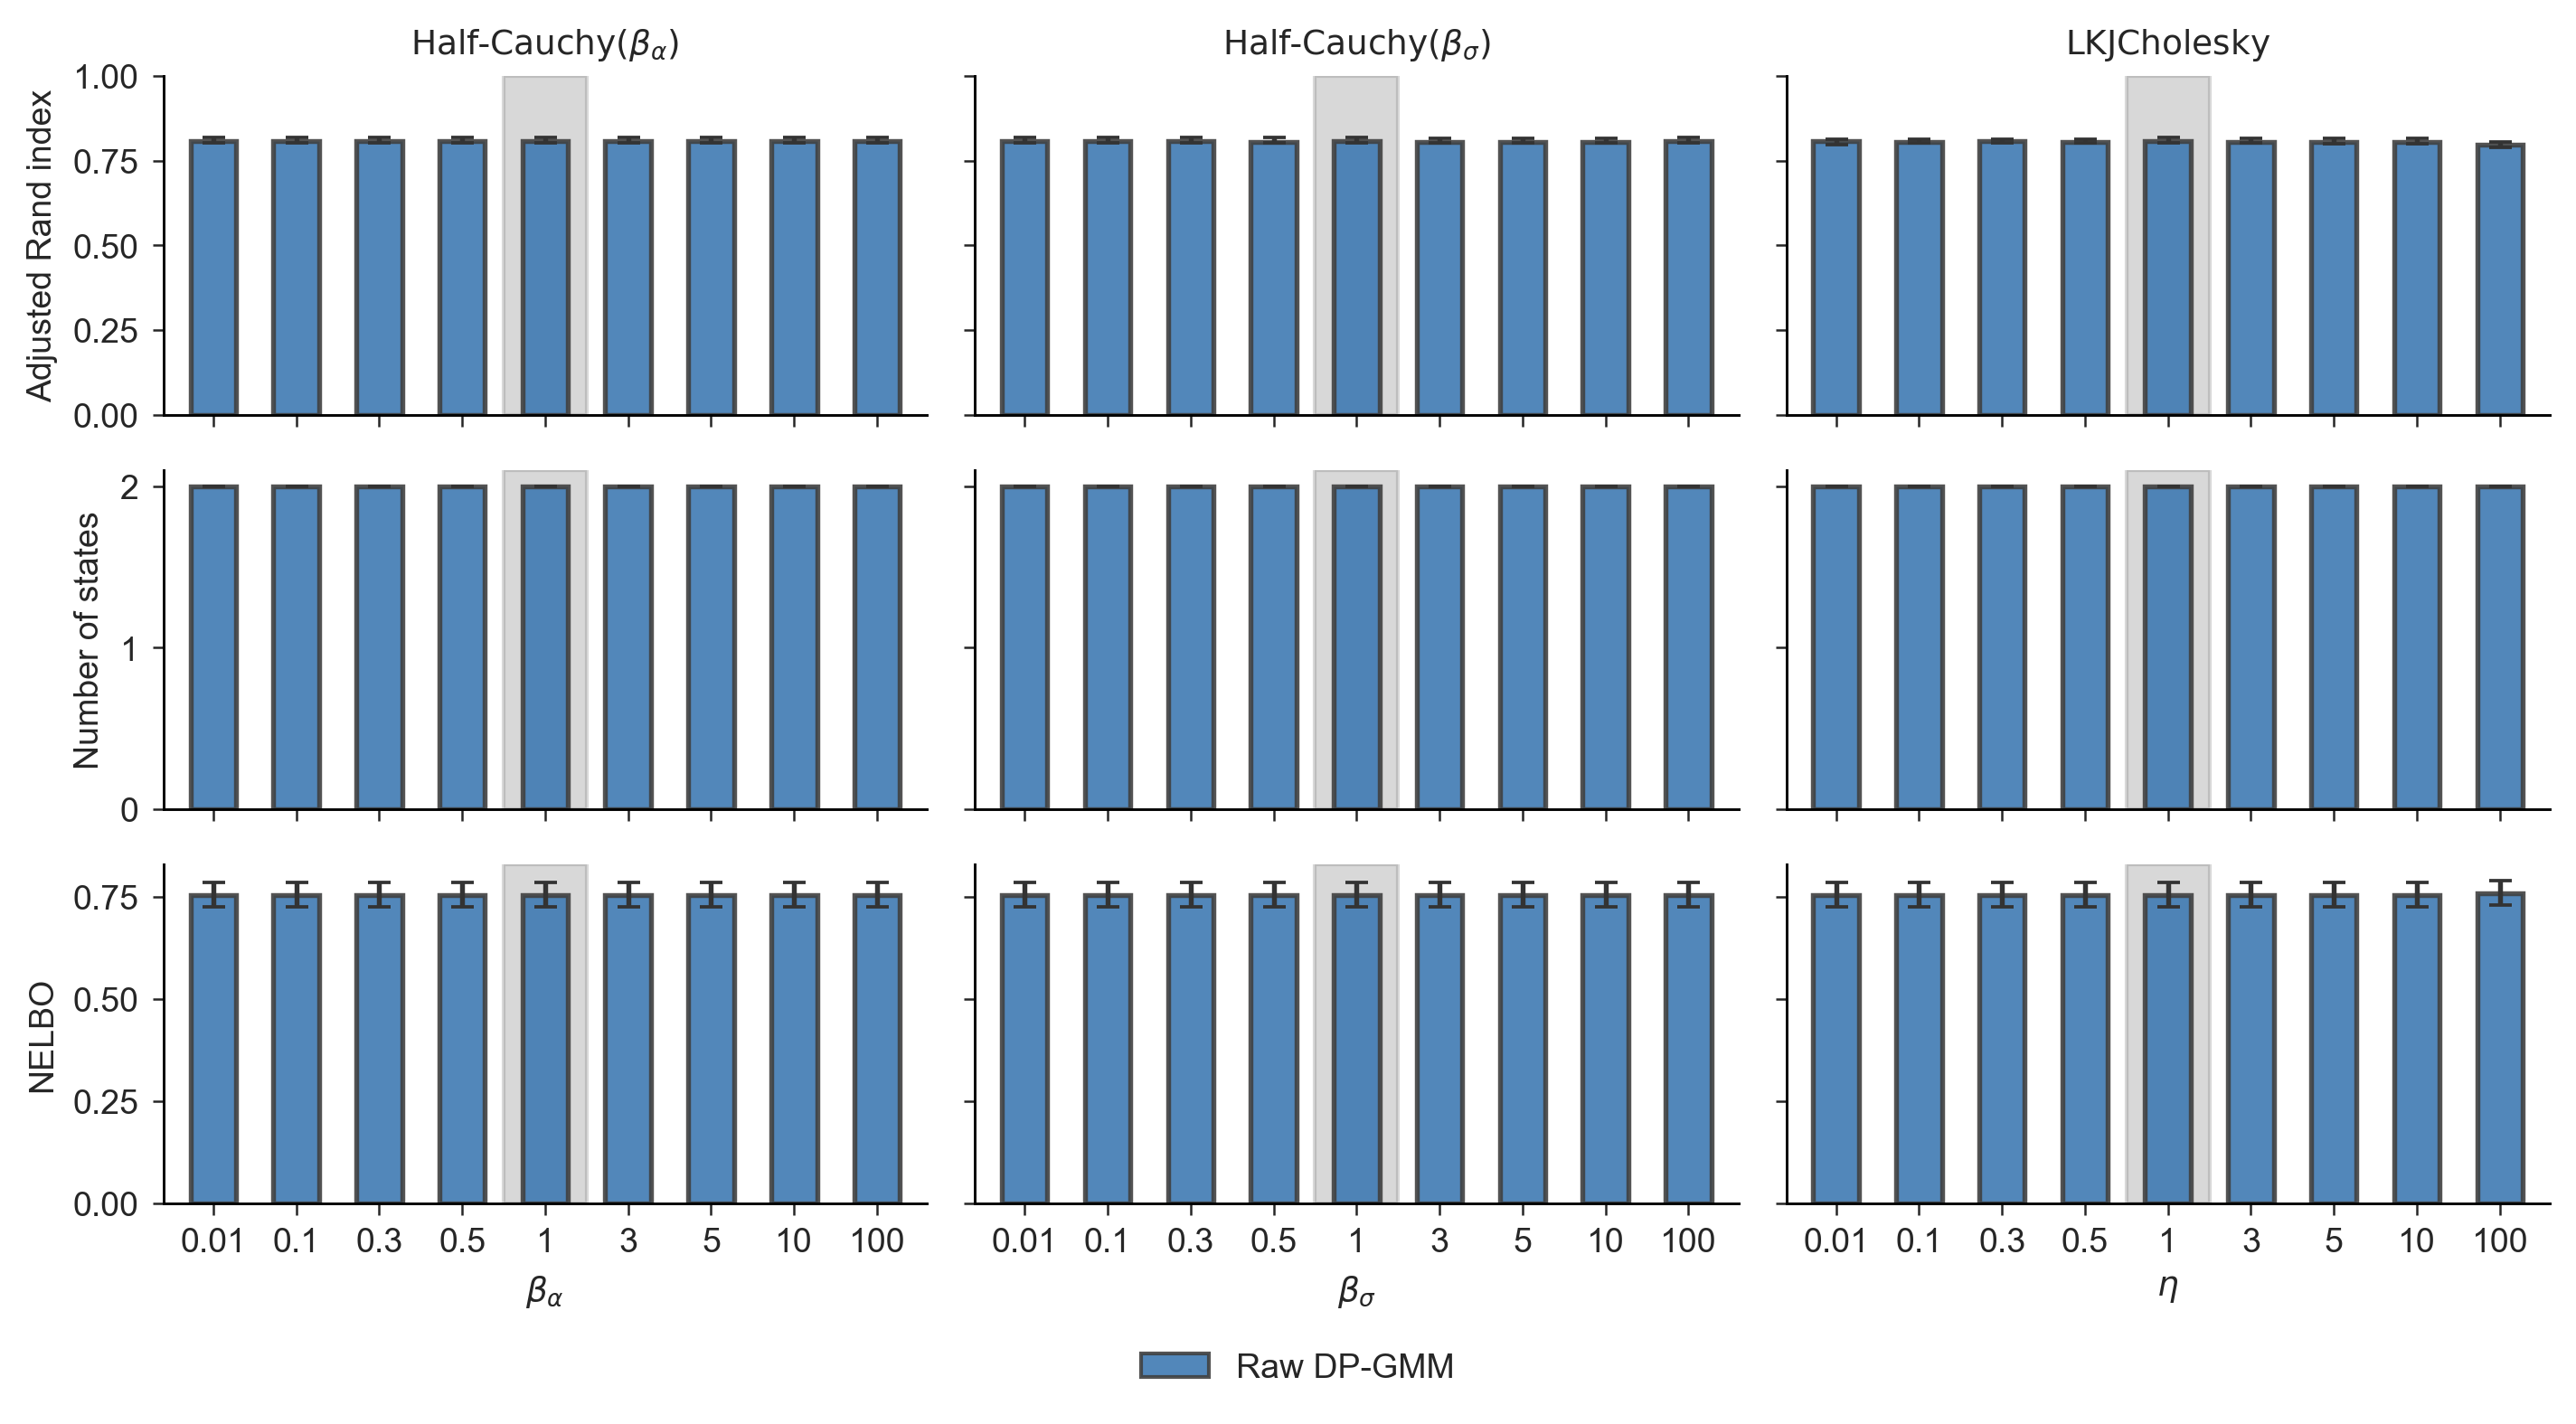

In [102]:
# Requires: df, prior_range, FIG_WIDTH, and fig_dir.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator


method = "DP-GMM"
bar_color = "#3F7AB3"
bar_width = 0.55

prior_names = [
    "alpha_prior_scale",
    "sigma_prior_scale",
    "lkj_concentration",
]

prior_titles = [
    r"$\mathrm{Half}$-$\mathrm{Cauchy}(\beta_{\alpha})$",
    r"$\mathrm{Half}$-$\mathrm{Cauchy}(\beta_{\sigma})$",
    r"$\mathrm{LKJCholesky}$",
]

prior_xlabels = [
    r"$\beta_{\alpha}$",
    r"$\beta_{\sigma}$",
    r"$\eta$",
]

# Baseline prior value shared by all three parameters.
baseline_value = 1.0

prior_order = sorted(
    {float(value) for value in prior_range} | {baseline_value}
)
order_labels = [f"{value:g}" for value in prior_order]
x_positions = np.arange(len(prior_order))
baseline_position = prior_order.index(baseline_value)

score_metric = "ari"  # "mcc", "ari", or "kappa"
score_labels = {
    "mcc": "MCC",
    "ari": "Adjusted Rand index",
    "kappa": "Cohen's kappa",
}

score_metric = score_metric.strip().lower()
if score_metric not in score_labels:
    raise ValueError("score_metric must be 'mcc', 'ari', or 'kappa'.")

score_ylim = (0, 1)  # Set to None to retain automatic limits.
metrics = [score_metric, "num_active_states", "loss"]
metric_labels = [
    score_labels[score_metric],
    "Number of states",
    "NELBO",
]

df_selected = df.loc[
    df["method"].eq(method)
    & df["prior_name"].isin(["baseline", *prior_names])
].copy()

df_selected["prior_value"] = pd.to_numeric(
    df_selected["prior_value"], errors="raise"
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(FIG_WIDTH + 2, 5),
    sharex="col",
    sharey="row",
)


def plot_median_iqr(ax, data, metric):
    """Draw centered median bars with error bars spanning Q25–Q75."""
    summary = (
        data.groupby("prior_label", observed=True)[metric]
        .agg(
            median="median",
            q25=lambda values: values.quantile(0.25),
            q75=lambda values: values.quantile(0.75),
        )
        .reindex(order_labels)
    )

    valid = summary.notna().all(axis=1).to_numpy()
    if not valid.any():
        return

    positions = x_positions[valid]
    medians = summary.loc[valid, "median"].to_numpy()
    q25 = summary.loc[valid, "q25"].to_numpy()
    q75 = summary.loc[valid, "q75"].to_numpy()

    ax.bar(
        positions,
        medians,
        width=bar_width,
        color=bar_color,
        edgecolor="0.25",
        linewidth=1.3,
        alpha=0.9,
        zorder=2,
    )

    ax.errorbar(
        positions,
        medians,
        yerr=np.vstack([medians - q25, q75 - medians]),
        fmt="none",
        ecolor="0.20",
        elinewidth=1.3,
        capsize=3,
        capthick=0.9,
        zorder=3,
    )


for col, (prior_name, prior_title, prior_xlabel) in enumerate(
    zip(prior_names, prior_titles, prior_xlabels)
):
    # Include baseline observations in every column.
    df_plot = df_selected.loc[
        df_selected["prior_name"].isin(["baseline", prior_name])
    ].copy()

    df_plot["prior_label"] = df_plot["prior_value"].map(
        lambda value: f"{value:g}"
    )

    # Preserve the existing NELBO deduplication:
    # (sample_id, prior_id) identifies one fit in this sweep.
    df_loss = df_plot.drop_duplicates(
        subset=["sample_id", "prior_id"]
    )

    for row, (metric, ylabel) in enumerate(
        zip(metrics, metric_labels)
    ):
        ax = axes[row, col]

        # Highlight the baseline prior value.
        ax.axvspan(
            baseline_position - 0.5,
            baseline_position + 0.5,
            color="gray",
            alpha=0.30,
            zorder=0,
        )

        plot_median_iqr(
            ax=ax,
            data=df_loss if metric == "loss" else df_plot,
            metric=metric,
        )

        if row == 0:
            ax.set_title(prior_title)

        ax.set_ylabel(ylabel if col == 0 else "")
        ax.set_xlabel(prior_xlabel if row == 2 else "")

        ax.set_xticks(x_positions)
        ax.set_xticklabels(order_labels)
        ax.set_xlim(-0.6, len(prior_order) - 0.4)

        if metric == "num_active_states":
            ax.yaxis.set_major_locator(MaxNLocator(integer=True))

# Limits are shared across each row.
if score_ylim is not None:
    axes[0, 0].set_ylim(*score_ylim)

loss_values = df_selected["loss"].dropna()
if not loss_values.empty and loss_values.ge(0).all():
    axes[2, 0].set_ylim(bottom=0)

# Single-method legend.
fig.legend(
    handles=[
        Patch(
            facecolor=bar_color,
            edgecolor="0.25",
            alpha=0.9,
            label="Raw DP-GMM",
        )
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=1,
    frameon=False,
)

fig.subplots_adjust(
    left=0.08,
    right=0.99,
    top=0.95,
    bottom=0.12,
    hspace=0.22,
    wspace=0.12,
)

save_path = Path(fig_dir) / f"prior_sensitivity_{score_metric}"
save_path.parent.mkdir(parents=True, exist_ok=True)

for fmt in ["svg", "pdf"]:
    fig.savefig(
        save_path.with_suffix(f".{fmt}"),
        format=fmt,
        bbox_inches="tight",
        pad_inches=0.1,
        dpi=900,
    )

print(f"Figures saved to: {save_path}.svg and {save_path}.pdf")
plt.show()

# approximation error (Ishwaran & James Theorem 2)

In [85]:
from math import exp
from scipy.stats import gamma

n = 45_000 - 21 + 1  # embedded observations per recording

def epsilon(K, alpha=1.0):
    if K == 1:
        return 4.0
    S = gamma(K - 1, scale=1 / alpha)
    return 4 * S.expect(lambda s: 1 - (1 - exp(-s))**n)

bounds = {K: epsilon(K) for K in range(1, 36)}

for K in range(3, 36, 4):
    print(f"K={K:2d}  epsilon={bounds[K]:.6f}")

first_K = min(K for K in bounds if bounds[K] < 0.01)
print(f"First K below 0.01: {first_K}")

K= 3  epsilon=3.998996
K= 7  epsilon=3.843517
K=11  epsilon=2.695895
K=15  epsilon=1.019907
K=19  epsilon=0.205407
K=23  epsilon=0.025140
K=27  epsilon=0.002192
K=31  epsilon=0.000157
K=35  epsilon=0.000010
First K below 0.01: 25
